# TRABAJO PRACTICO INTEGRADOR - SEGUNDO PARCIAL
#### INTEGRANTES:
- Bianciotto Sofia - 1241171
- Cebreiros Juana - 1238673
- Lacava Giuliana - 1239334
- Lazaro Martina - 1238503
##### TEMA: Utilizaremos un dataset de una veterinaria para construir un modelo de clasificación en dos etapas: primero predecir si el paciente está sano o enfermo y, si está enfermo, identificar si presenta una afección de piel, de oído o ambas (mixta).

**Fuente del dataset:** https://www.kaggle.com/datasets/blaineee/veterinary-health-and-parasitology-dataset

### Carga de los datos

In [3]:
# Librerías para EDA
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Librerías para Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Métricas de clasificación
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [4]:
df = pd.read_csv("Vet_Clinical_Dataset.csv")
print("El Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:")
df.shape

El Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:


(2000, 15)

In [5]:
# Creamos una columna para distinguir si el paciente está sano o enfermo
df['estado_salud'] = df['definitive diagnosis'].apply(lambda x: 'sano' if x == 'healthy' else 'enfermo')

### EDA INICIAL - PREPARACIÓN Y LIMPIEZA DE DATOS

En los siguientes cuadros de codigo, revisaremos el dataset y los datos del mismo, verificando si hay valores nulos, duplicados, faltantes. Luego analizaremos que hacer frente a cada problema encontrado. 

In [6]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake location', 'Body condition score', 'wood lamp fungal',
       'definitive diagnosis', 'estado_salud'],
      dtype='str')

### Qué información da cada columna
- `Patient ID`: código único de cada caso.
- `ownership_status`: origen del animal (`owned` = con dueño, `rescued` = rescatado, `lost_rescued` = perdido y rescatado).
- `intake date`: fecha en que el animal fue llevado a la consulta (solo animales rescatados / perdidos).
- `booking date`: fecha de una consulta con reserva previa (solo animales con dueño).
- `species`: especie (`canine` = perro, `feline` = gato).
- `breed`: raza.
- `age`: edad (viene como texto: "4 years", "12 weeks"...).
- `sex`: sexo.
- `weight`: peso en kg.
- `temperature`: temperatura corporal en °C.
- `heart rate`: latidos por minuto.
- `intake location`: zona de la ciudad donde se encontró al animal.
- `Body condition score`: condición corporal de 1 (escuálido) a 9 (obeso).
- `wood lamp fungal`: resultado de la lámpara de Wood (test para hongos): `Positive` / `Negative`.
- `definitive diagnosis`: diagnóstico final del veterinario (**es lo que queremos predecir**).

In [7]:
df.head(3) #Los primeros 3 registros del dataset


,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis,enfermo
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo


In [8]:
df.tail(3) #Los últimos 3 registros del dataset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm,enfermo
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
1999,24034062,rescued,3/15/2024,NaN,feline,Siamese,12 weeks,female,2.0,38.3,NaN,"Bel-Air, Makati City",7.0,Negative,Ear Mites and Yeast Otitis,enfermo


In [9]:
df.sample(5) #5 registros aleatorios del datset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
678,23125591,rescued,12/19/2023,NaN,feline,Puspin,8 months,male,3.5,38.9,156.0,"East Rembo, Makati City",6.0,Positive,Ringworm and Yeast Otitis,enfermo
1269,25028544,rescued,2/18/2025,NaN,feline,Puspin,7 years,male,4.0,39.2,174.0,"Pembo, Makati City",6.0,Positive,Ringworm and Yeast Otitis,enfermo
1493,23101235,rescued,10/28/2023,NaN,feline,Puspin,3 months,female,2.0,38.7,213.0,"San Antonio, Makati City",5.0,Negative,Atopic Dermatitis,enfermo
360,25116940,rescued,11/20/2025,NaN,feline,Siamese,1 years,female,4.0,38.5,NaN,"Urdaneta, Makati City",6.0,Negative,Ear Mites and Yeast Otitis,enfermo
1111,24044690,owned,NaN,2024-04-09,canine,Chihuahua,10 years,female,4.4,38.4,114.0,NaN,6.0,Positive,Ringworm and Yeast Otitis,enfermo


In [10]:
df.info() #Panorama general del dataset. Cantidad de filas, columnas, nombres de las columnas, cantidad de valores no nulos por columna y tipo de dato de cada columna.

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient ID            2000 non-null   int64  
 1   ownership_status      2000 non-null   str    
 2   intake date           866 non-null    str    
 3   booking date          1134 non-null   str    
 4   species               2000 non-null   str    
 5   breed                 2000 non-null   str    
 6   age                   2000 non-null   str    
 7   sex                   2000 non-null   str    
 8   weight                2000 non-null   float64
 9   temperature           2000 non-null   float64
 10  heart rate            1689 non-null   float64
 11  intake location       866 non-null    str    
 12  Body condition score  1942 non-null   float64
 13  wood lamp fungal      2000 non-null   str    
 14  definitive diagnosis  2000 non-null   str    
 15  estado_salud          2000 non-n

Podemos observar que el dataset contiene 2000 filas y 15 columnas originales (df.info() muestra 16 porque ya agregamos estado_salud), de las cuales 10 no tienen ningun valor nulo. "intake date" - "booking date" - "heart rate" - "intake location" - "body condition score" tienen valores nulos. 

In [11]:
df.describe() #Resumen estadístico de las variables numericas

,Patient ID,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,35.800000,39.300000,230.000000,7.000000


- count: cantidad de valores no nulos
- mean: promedio
- std: desvio estandar
- min: valor minimo 
- 25% - 75%: primer y tercer cuartil
- 50%: mediana
- max: valor maximo

observaciones:
- "heart rate" y "body condition score" tiene valores nulos 
- este no es un analisis significativo para la variable Patient ID, ya que es una variable unica de cada paciente. Serviría mas analizarla como "object". (ver de hacer una transformacion a object)
- en "weight" y "heart rate" la media se encuentra alejada de la mediana (50%), tienen un desvio estandar elevado, por lo que los datos estan dispersos. Puede significar la presencia de algun outlier.

In [12]:
df.describe(include="object") #Ahora aplicado a las variables categoricas 

C:\Users\lacav\AppData\Local\Temp\ipykernel_12200\2158270276.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") #Ahora aplicado a las variables categoricas


,ownership_status,intake date,booking date,species,breed,age,sex,intake location,wood lamp fungal,definitive diagnosis,estado_salud
count,2000,866,1134,2000,2000,2000,2000,866,2000,2000,2000
unique,3,586,678,2,13,26,2,16,2,13,2
top,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,"South Cembo, Makati City",Negative,Ear Mites and Yeast Otitis,enfermo
freq,1134,4,6,1199,484,131,1008,69,1683,181,1884


- count: valores no nulos
- unique: cantidad de valores unicos
- top: valor mas frecuente
- freq: frecuencia del valor mas frecuente

observaciones: 
- sobre "ownership status":     
        - el valor mas repetido es "owned" apareciendo 1134 veces de 2000 registros totales, lo que significa que más de la mitad de los animales atendidos tenían dueño. 
- sobre "intake date":
       - hay varios valores faltantes, de 2000 ingresos, solo se registraron 866 en esta categoría. Las fechas de ingreso estan muy distribuidas, no existe una en particular que acumule un gran porcentaje de animales ingresados. 
- sobre "booking date":
        - lo mismo que para la variable anterior, presenta muchos datos faltantes 
- sobre "species":
        - hay solamente 2 tipos de especies, siendo apenas más de la mitad "canine"
- sobre "breed":
        - hay 13 razas diferentes, siendo "Aspin" la más frecuente, representando el 24,2% de los registros
- sobre "age":
        - de 26 edades registradas, ninguna representa una gran mayoria de los datos. 
- sobre "sex":
        - el sexo femenino esta muy levemente más repetido que el sexo masculino (los dos unicos valores posibles)
- sobre "intake location":
        - ninguna de las 16 ubicaciones esta mucho más repetida que el resto. Hay que considerar que hay más de la mitad de valores faltantes
- sobre "wood lamp fungal":
        - la mayoria de los resultados dio negativo (el 84,15%). Solo el 15,85% dio positivo. Todos los animales fueron sometidos al test.
- sobre "definitive diagnosis":
        - hubo 13 diagnosticos distintos, el mas repetido "ear mites and yeast otitis", sin predominar ampliamente por sobre el resto

In [13]:
df.describe(include="all") #Esta es la forma de incluir lo de ambas tablas anteriores en una sola

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
count,2.000000e+03,2000,866,1134,2000,2000,2000,2000,2000.000000,2000.000000,1689.000000,866,1942.000000,2000,2000,2000
unique,NaN,3,586,678,2,13,26,2,NaN,NaN,NaN,16,NaN,2,13,2
top,NaN,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,NaN,NaN,NaN,"South Cembo, Makati City",NaN,Negative,Ear Mites and Yeast Otitis,enfermo
freq,NaN,1134,4,6,1199,484,131,1008,NaN,NaN,NaN,69,NaN,1683,181,1884
mean,2.404418e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.652150,38.711250,129.512729,NaN,4.845520,NaN,NaN,NaN
std,8.212429e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.340566,0.294859,41.831217,NaN,1.453319,NaN,NaN,NaN
min,2.301009e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700000,38.000000,66.000000,NaN,3.000000,NaN,NaN,NaN
25%,2.309690e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000,38.500000,96.000000,NaN,3.000000,NaN,NaN,NaN
50%,2.406290e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.500000,38.700000,115.000000,NaN,5.000000,NaN,NaN,NaN
75%,2.503390e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.700000,39.000000,165.000000,NaN,6.000000,NaN,NaN,NaN


Tranformaremos la variable "age" a numerica para poder trabajar mejor con ella. La edad es un dato numerico actualmente expresado como texto, para poder hacer operaciones, comparaciones e incluso el análisis estadístico, es necesario que pertezca a la categoria de variables numericas. 

In [14]:
df["age"].unique() #Observamos los posibles valores y el tipo (str). La tranformaremos a una variable numerica

<StringArray>
[  '4 years',   '9 years',  '12 weeks',  '12 years',   '3 years',   '6 years',
  '10 years',  '9 months',   '5 years', '11 months',   '1 years',  '5 months',
  '8 months',  '7 months',   '8 weeks',   '7 years',  '11 years',   '9 weeks',
   '2 years',  '6 months', '10 months',  '4 months',   '8 years',  '3 months',
  '11 weeks',  '10 weeks']
Length: 26, dtype: str

In [15]:
#Creamos una función de apoyo para la transformación
def convertir_age(edad):
    edad = str(edad).lower().strip()
    if "years" in edad:
        return float(edad.replace("years" , "").strip())
    elif "months" in edad:
        return float(edad.replace("months" , "").strip()) / 12
    elif "weeks" in edad:
        return float(edad.replace("weeks" , "").strip()) / 52
    else:
        return "edad no valida"

Aclaración: ahora las edades estaran todas expresadas en funcion de años, es decir, 6 meses sera 0.5 (años), 11 semanas sera 0.2115538... (años).

In [16]:
df["age"] = df["age"].apply(convertir_age)
df["age"]

0        4.000000
1        9.000000
2        0.230769
3       12.000000
4        3.000000
          ...    
1995     0.750000
1996     7.000000
1997     0.211538
1998    10.000000
1999     0.230769
Name: age, Length: 2000, dtype: float64

In [17]:
df["age"].dtype

dtype('float64')

In [18]:
df.describe() #Ahora podemos incluir la variable "age" en el analisis de las numericas

,Patient ID,age,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,2.729029,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,3.436170,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.153846,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,0.416667,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,0.833333,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,5.000000,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,12.000000,35.800000,39.300000,230.000000,7.000000


In [19]:
df["ownership_status"].value_counts() #Cuantas animales tienen dueño, fueron rescatados o estaban perdidos y fueron rescatados

ownership_status
owned           1134
rescued          684
lost_rescued     182
Name: count, dtype: int64

De 2000 animales: 56,7% tenían dueño - 32,4% fueron rescatados - 9,1% eran perdidos y fueron rescatados

In [20]:
df["breed"].value_counts() #Cuantos ingresos hay de cada raza

breed
Aspin                 484
Puspin                342
Persian               121
Domestic Shorthair    120
Siberian Husky        113
Chihuahua             110
British Shorthair     109
Siamese               109
French Bulldog        109
Shih Tzu              102
Golden Retriever       98
Pomeranian             93
Poodle                 90
Name: count, dtype: int64

In [21]:
df["intake location"].value_counts() #Cuantos ingresos hay por cada ubicación

intake location
South Cembo, Makati City            69
Palanan, Makati City                64
Pitogo, Makati City                 64
Urdaneta, Makati City               62
Bel-Air, Makati City                56
Guadalupe Nuevo, Makati City        56
East Rembo, Makati City             55
Pembo, Makati City                  54
San Lorenzo, Makati City            53
Guadalupe Viejo, Makati City        53
Makati Central Business District    51
Rizal, Makati City                  49
West Rembo, Makati City             47
Comembo, Makati City                46
Poblacion, Makati City              46
San Antonio, Makati City            41
Name: count, dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

No hay ningun registro con exactamente los mismos valores en todas sus columnas.

In [23]:
df.isnull().sum() #Muestra los valores nulos por columna

Patient ID                 0
ownership_status           0
intake date             1134
booking date             866
species                    0
breed                      0
age                        0
sex                        0
weight                     0
temperature                0
heart rate               311
intake location         1134
Body condition score      58
wood lamp fungal           0
definitive diagnosis       0
estado_salud               0
dtype: int64

Podemos observar:
- "intake date" tiene 1134 valores nulos.
- "booking date" tiene 866 valores nulos.
- "heart rate" tiene 311 valores nulos.
- "intake location" tiene 1134 valores nulos. 
- "body condition score" tiene 58 valores nulos.
-  El resto de las columnas no presentan valores nulos. 

In [24]:
nulos_porcentaje = df.isnull().sum() / (len(df)) * 100

print(nulos_porcentaje) #Muestra el porcentaje de datos nulos por columna

Patient ID               0.00
ownership_status         0.00
intake date             56.70
booking date            43.30
species                  0.00
breed                    0.00
age                      0.00
sex                      0.00
weight                   0.00
temperature              0.00
heart rate              15.55
intake location         56.70
Body condition score     2.90
wood lamp fungal         0.00
definitive diagnosis     0.00
estado_salud             0.00
dtype: float64


In [25]:
df[df.isnull().any(axis=1)] #Visualización de registros con al menos 1 dato faltante

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4.000000,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9.000000,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis,enfermo
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,0.230769,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
3,23014013,owned,NaN,2023-01-07,feline,Puspin,12.000000,female,4.1,38.7,NaN,NaN,3.0,Negative,Ear Mites and Yeast Otitis,enfermo
4,24073658,rescued,7/17/2024,NaN,canine,Aspin,3.000000,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites,enfermo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,25097643,owned,NaN,2025-09-02,canine,Aspin,0.750000,female,13.3,39.0,104.0,NaN,7.0,Negative,Bacterial Dermatitis,enfermo
1996,23052008,rescued,5/20/2023,NaN,canine,French Bulldog,7.000000,female,22.0,38.9,NaN,Makati Central Business District,5.0,Negative,Atopic Dermatitis,enfermo
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,0.211538,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm,enfermo
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10.000000,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo


Eliminaremos las columnas "Patient ID", "intake date" y "booking date" ya que no son relevantes para el analisis que relizaremos, y además las últimas dos, poseen una gran volumen de nulos, por lo que seria muy dificil hacer una imputacion acertada.

In [26]:
df = df.drop(columns=["Patient ID" , "intake date" , "booking date"])

In [27]:
df.columns #Confirmamos que hayan sido eliminadas

Index(['ownership_status', 'species', 'breed', 'age', 'sex', 'weight',
       'temperature', 'heart rate', 'intake location', 'Body condition score',
       'wood lamp fungal', 'definitive diagnosis', 'estado_salud'],
      dtype='str')

### Imputacion de nulos

Para la variable "heart rate", separaremos la imputacion segun felinos y caninos, ya que segun la especie, varian mucho los valores. Completarlos con una media general, puede terminar en un valor poco representativo para amabas especies. 

In [28]:
df.groupby("species")["heart rate"].median()

species
canine    102.0
feline    172.0
Name: heart rate, dtype: float64

In [29]:
df["heart rate"] = df.groupby("species")["heart rate"].transform(
    lambda x: x.fillna(x.median())
)

In [30]:
df["Body condition score"] = df["Body condition score"].fillna(df["Body condition score"].median())

In [31]:
df["intake location"] = df["intake location"].fillna("Desconocido")

In [32]:
df.head(15) #Observamos el dataset sin nulos

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
0,rescued,canine,Aspin,4.000000,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
1,owned,canine,Shih Tzu,9.000000,male,9.7,39.1,102.0,Desconocido,4.0,Negative,Atopic Dermatitis,enfermo
2,owned,canine,Golden Retriever,0.230769,male,11.7,39.1,102.0,Desconocido,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
3,owned,feline,Puspin,12.000000,female,4.1,38.7,172.0,Desconocido,3.0,Negative,Ear Mites and Yeast Otitis,enfermo
4,rescued,canine,Aspin,3.000000,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites,enfermo
5,owned,canine,Aspin,6.000000,male,10.3,39.2,102.0,Desconocido,4.0,Negative,Yeast Dermatitis,enfermo
6,owned,feline,British Shorthair,10.000000,female,5.6,38.9,172.0,Desconocido,5.0,Negative,Yeast Otitis,enfermo
7,lost_rescued,canine,Chihuahua,0.750000,male,2.7,38.7,126.0,"Urdaneta, Makati City",5.0,Negative,Ear Mites and Yeast Otitis,enfermo
8,rescued,feline,Puspin,5.000000,male,4.9,38.2,192.0,"Rizal, Makati City",4.0,Negative,Ear Mites and Yeast Otitis,enfermo
9,owned,canine,Poodle,0.750000,female,5.7,39.0,102.0,Desconocido,6.0,Negative,Bacterial Otitis,enfermo


In [33]:
df.isnull().sum()

ownership_status        0
species                 0
breed                   0
age                     0
sex                     0
weight                  0
temperature             0
heart rate              0
intake location         0
Body condition score    0
wood lamp fungal        0
definitive diagnosis    0
estado_salud            0
dtype: int64

#### BUSQUEDA DE OUTLIERS

Para buscar valores imposibles, debedos determinar que cosas significarian que el dato no sea validos:
- Animales con edades negativas, o muy grandes. La esperanza de vida entre ambas especies es muy similar, por lo que tomaremos a los mayores de 35 años, como una edad imposible. 
- Animales con peso nulo, o negativo. 
- Temperaturas corporales negativas, muy bajas o muy elevadas
- Frecuencias cardiacas negativas
- Puntaje de condicion corporal fuera de la escala utilizada

In [34]:
# 1. EDAD

print("EDADES NEGATIVAS (VALORES IMPOSIBLES):")

display(df[df["age"] <= 0])

print("EDADES MAYORES A 35 AÑOS (OUTLIERS EXTREMOS):")

display(df[df["age"] > 35])



# 2. PESO

print("PESOS IGUALES O MENORES A 0 (VALORES IMPOSIBLES):")

display(df[df["weight"] <= 0])

print("FELINOS CON PESO MAYOR A 30 KG (outlier):")

display(df[
    (df["species"] == "feline") &
    (df["weight"] > 30)
])

print("CANINOS CON PESO MAYOR A 120 KG (outlier):")

display(df[
    (df["species"] == "canine") &
    (df["weight"] > 120)
])



# 3. TEMPERATURA

print("TEMPERATURAS NEGATIVAS O IGUALES A 0 (valor imposible):")

display(df[df["temperature"] <= 0])

print("TEMPERATURAS MENORES A 30 °C (outlier):")

display(df[
    (df["temperature"] > 0) &
    (df["temperature"] < 30)
])

print("TEMPERATURAS MAYORES A 43 °C (outlier):")

display(df[df["temperature"] > 43])



# 4. FRECUENCIA CARDÍACA

print("FRECUENCIAS CARDÍACAS NEGATIVAS O IGUALES A 0 (valor imposible):")

display(df[df["heart rate"] <= 0])

print("FELINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):")

display(df[
    (df["species"] == "feline") &
    ((df["heart rate"] < 65) | (df["heart rate"] > 250))
])

print("CANINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):")

display(df[
    (df["species"] == "canine") &
    ((df["heart rate"] < 40) | (df["heart rate"] > 230))
])



# 5. BODY CONDITION SCORE

print("PUNTAJES FUERA DE LA ESCALA DE 1 A 9 (valores imposibles):")

display(df[
    (df["Body condition score"] < 1) |
    (df["Body condition score"] > 9)
])


EDADES NEGATIVAS (VALORES IMPOSIBLES):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


EDADES MAYORES A 35 AÑOS (OUTLIERS EXTREMOS):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


PESOS IGUALES O MENORES A 0 (VALORES IMPOSIBLES):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


... (14 outputs left out)

CANINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


PUNTAJES FUERA DE LA ESCALA DE 1 A 9 (valores imposibles):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


No hay ningún valor imposible según los rangos que definimos para cada columna. Más adelante, los boxplots muestran valores atípicos estadísticos (sobre todo en peso) que decidimos conservar: corresponden a razas y especies de distinto tamaño y no a errores de carga.

## Análisis Exploratorio de Datos- EDA
En esta sección se realizará un análisis exploratorio del dataset veterinario, con el objetivo de comprender la distribución de las variables, identificar posibles patrones y estudiar las relaciones que podrían resultar relevantes para predecir el estado de los pacientes.

 ### Distribucion de las variables numéricas

#### Peso, temperatura, edad y frecuencia cardiaca - Histogramas
Comenzamos analizando gráficamente la distribución de las principales variables numéricas del dataset: peso, temperatura corporal, frecuencia cardíaca y edad.
Para ello, utilizaremos histogramas, que permiten visualizar la frecuencia con la que se presentan los valores de cada variable, agrupándolos en intervalos.
El objetivo de este análisis es identificar los valores más frecuentes, observar la forma de las distribuciones y detectar posibles asimetrías o concentraciones de datos. 

In [35]:
def plot_histogramas_univariado(df):
    '''
    Grafica los histogramas de peso, temperatura, edad
    y frecuencia cardíaca de los pacientes.
    '''

    # Histogramas
    plt.figure(figsize=(16, 4))

    # Subplot Histograma peso
    plt.subplot(1, 4, 1)
    sns.histplot(data=df, x='weight', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Peso')
    plt.xlabel('Peso (kg)')

    # Subplot Histograma temperatura
    plt.subplot(1, 4, 2)
    sns.histplot(data=df, x='temperature', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Temperatura')
    plt.xlabel('Temperatura (C°)')

    # Subplot Histograma frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.histplot(data=df, x='heart rate', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Frecuencia cardíaca')
    plt.xlabel('Frecuencia cardíaca (lpm)')

    # Subplot Histograma edad
    plt.subplot(1, 4, 4)
    sns.histplot(data=df, x='age', bins=15,
                color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Edad')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Distribución de las variables numéricas',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()

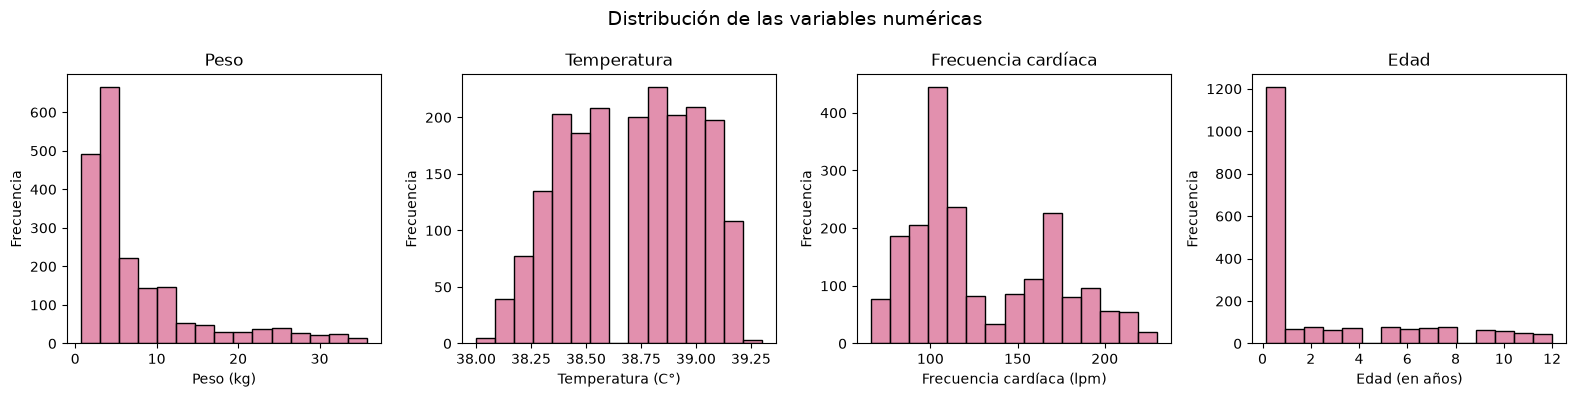

In [36]:
plot_histogramas_univariado(df)


Interpretacion: El peso presenta una distribución asimétrica positiva, con una mayor concentración de pacientes en los valores bajos y una menor frecuencia de pesos elevados.
La temperatura corporal presenta una distribución relativamente concentrada, sin una asimetría muy marcada.
La frecuencia cardíaca muestra diferentes concentraciones de valores, que podrían estar relacionadas con las características fisiológicas de las especies presentes en el dataset.
Por último, la edad presenta una distribución fuertemente asimétrica positiva, con una concentración elevada de pacientes jóvenes y una menor frecuencia de animales de mayor edad.
Estas observaciones permiten identificar patrones que justifican profundizar el análisis mediante comparaciones entre especies y estados de salud

#### Peso, temperatura, frecuencia cardiaca y edad- Boxplots
Para complementar el análisis realizado mediante histogramas, utilizaremos el diagrama: boxplots.
Este tipo de gráfico permite visualizar la mediana, los cuartiles, la dispersión de los datos y los posibles valores atípicos (outliers).
El objetivo es profundizar en el comportamiento de las variables e identificar posibles valores extremos que requieran un análisis adicional, considerando las diferencias entre las especies y razas presentes en el dataset.

In [37]:
def plot_boxplots_univariado(df):
    '''
    Grafica los boxplots de peso, temperatura, frecuencia cardíaca y edad de los pacientes.
    '''

    # Boxplots
    plt.figure(figsize=(16, 4))

    # Subplot Boxplot peso
    plt.subplot(1, 4, 1)
    sns.boxplot(data=df, x='weight', color='#d96b93')
    plt.xlabel('Peso (kg)')

    # Subplot Boxplot temperatura
    plt.subplot(1, 4, 2)
    sns.boxplot(data=df, x='temperature', color='#d96b93')
    plt.xlabel('Temperatura (C°)')

    # Subplot Boxplot frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.boxplot(data=df, x='heart rate', color='#d96b93')
    plt.xlabel('Frecuencia cardíaca (lpm)')
    # Subplot Boxplot edad
    plt.subplot(1, 4, 4)
    sns.boxplot(data=df, x='age', color='#d96b93')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Comparación de la distribución de cuatro variables numéricas',
        fontsize=14,
        ha='center'
    )

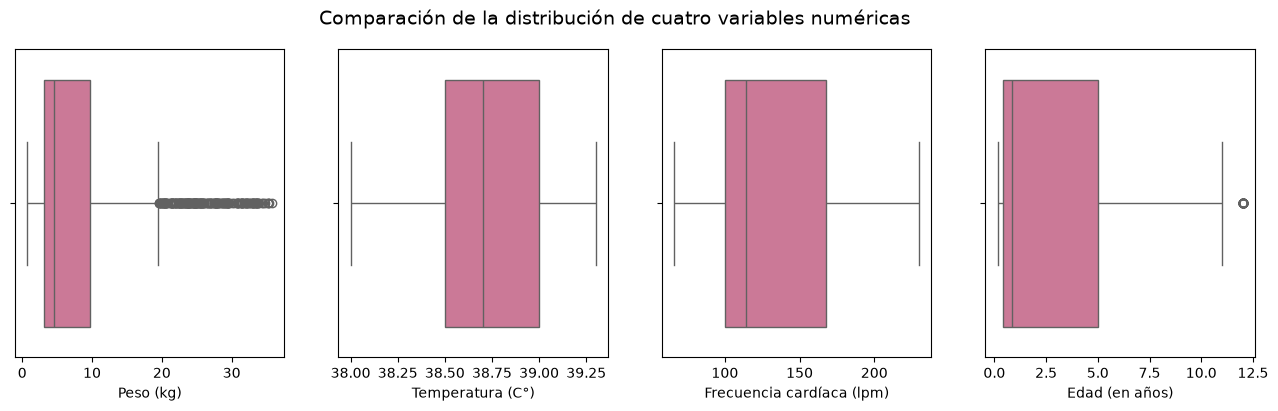

In [38]:
plot_boxplots_univariado(df)

Interpretación: El peso presenta numerosos posibles valores atípicos en los valores elevados. Sin embargo, estos no necesariamente representan errores, ya que podrían corresponder a diferencias de tamaño entre especies y razas.
La temperatura corporal presenta una caja relativamente estrecha y no se observan valores atípicos según el criterio del boxplot.
La frecuencia cardíaca presenta una dispersión considerable dentro de su escala, sin valores atípicos visibles. Sin embargo, este gráfico no permite distinguir claramente las diferentes concentraciones observadas anteriormente en el histograma.
Finalmente, la edad presenta una mediana próxima al primer cuartil, mientras que la caja se extiende hacia edades mayores. También se observa un posible valor atípico cercano a los 12 años, que no necesariamente representa un dato incorrecto.
En conjunto, estos gráficos permiten profundizar el análisis de las distribuciones y comprender mejor la variabilidad de las características de los pacientes.

### Distribucion de la condición corporal
La variable Body condition score representa la puntuación de la condición corporal de los pacientes veterinarios.
A diferencia de las variables analizadas anteriormente, se trata de una variable numérica discreta. Por este motivo, se utilizará un gráfico de barras para visualizar la frecuencia de cada puntuación registrada.

In [39]:
def graficar_barras(df, columna, titulo, hue=None, paso_y=None, paleta=None):
    '''
    Grafica la frecuencia de una variable mediante barras.
    Permite comparar grupos y modificar los intervalos del eje Y.
    '''

    plt.figure(figsize=(8, 4))

    if hue is None:
        sns.countplot(data=df, x=columna,
                      color='#d96b93', edgecolor='black')
    else:
        sns.countplot(data=df, x=columna, hue=hue,
                      palette=paleta, edgecolor='black')

    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel('Cantidad de pacientes')

    if paso_y is not None:
        limite_y = int(plt.ylim()[1])
        plt.yticks(range(0, limite_y + paso_y, paso_y))

    if hue is not None:
        plt.legend(title='Estado de salud' if hue == 'estado_salud' else hue)

    plt.show()



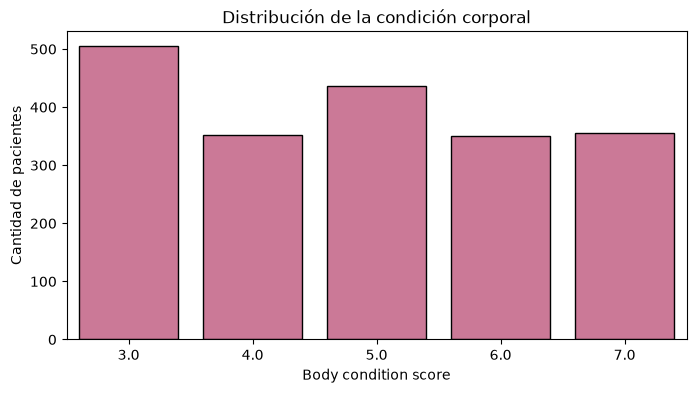

In [40]:
graficar_barras(df, 'Body condition score',
               'Distribución de la condición corporal')

Interpretacion: Se identifica que la puntuación 3 es la más frecuente, seguida por la puntuación 5. Por otro lado, las puntuaciones 4, 6 y 7 presentan frecuencias relativamente similares.
Esta distribución permite conocer las características generales de la condición corporal de los pacientes. Sin embargo, al tratarse de un análisis univariado, no es posible determinar si alguna puntuación está relacionada con un mayor número de enfermedades.

### Distribucion de las variables categoricas
A continuación, analizaremos la distribución de las principales variables categóricas del dataset.

### Especie y sexo
Comenzando por la especie y el sexo de los pacientes.
Utilizaremos gráficos de barras, que permiten representar la frecuencia de cada categoría y comparar la cantidad de pacientes pertenecientes a cada grupo.
El objetivo es conocer la composición general del conjunto de datos e identificar posibles diferencias en la representación de las categorías.

In [41]:

def plot_categoricas_univariado(df):
    '''
    Grafica la distribución de pacientes
    según especie y sexo.
    '''

    plt.figure(figsize=(12, 4))

    # Subplot de especies
    plt.subplot(1, 2, 1)
    sns.countplot(data=df, x='species',
                  color='#d96b93', edgecolor='black')
    plt.title('Distribución por especie')
    plt.xlabel('Especie')
    plt.ylabel('Cantidad de pacientes')

    # Subplot de sexo
    plt.subplot(1, 2, 2)
    sns.countplot(data=df, x='sex',
                  color='#e8a1be', edgecolor='black')
    plt.title('Distribución por sexo')
    plt.xlabel('Sexo')
    plt.ylabel('Cantidad de pacientes')

    plt.suptitle(
        'Distribución de las variables especie y sexo',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()


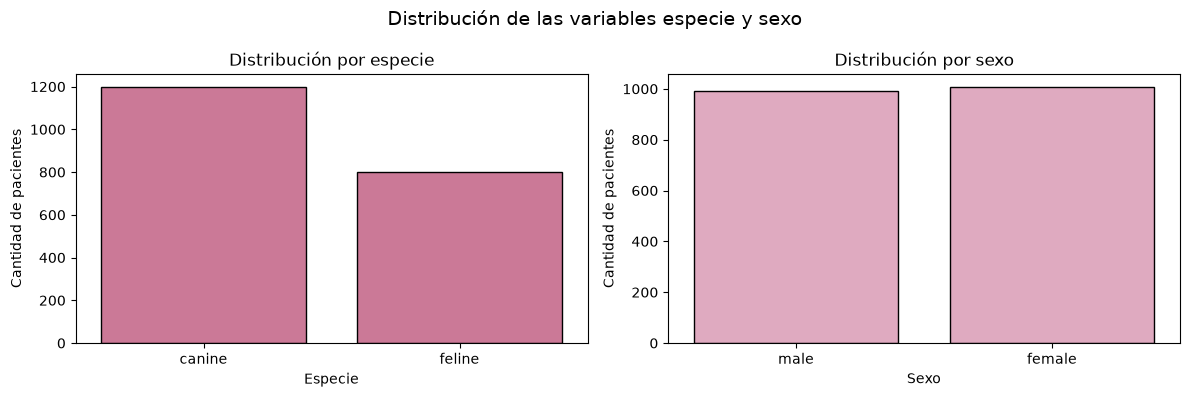

In [42]:
plot_categoricas_univariado(df)

Interpretacion: A partir de los gráficos de barras, se observa que el conjunto de datos presenta una mayor proporción de pacientes caninos (60 %) que felinos (40 %).
En cuanto al sexo, la distribución es relativamente equilibrada, con cantidades similares de machos y hembras.

### Frecuencia de las distintas razas
Acontinuación, analizaremos la distribución de los pacientes según su raza, utilizando un gráfico de barras horizontales para facilitar la visualización y comparación de las distintas categorías.
El objetivo es identificar cuáles son las razas más representadas en el conjunto de datos y observar si existen diferencias importantes en la cantidad de pacientes registrados por raza.

In [43]:

def plot_razas_univariado(df):
    '''
    Grafica la cantidad de pacientes por raza.
    '''

    plt.figure(figsize=(10, 6))

    sns.countplot(data=df, y='breed',
                  color='#d96b93', edgecolor='black')

    plt.title('Distribución de los pacientes según su raza')
    plt.xlabel('Cantidad de pacientes')
    plt.ylabel('Raza')

    plt.tight_layout()
    plt.show()


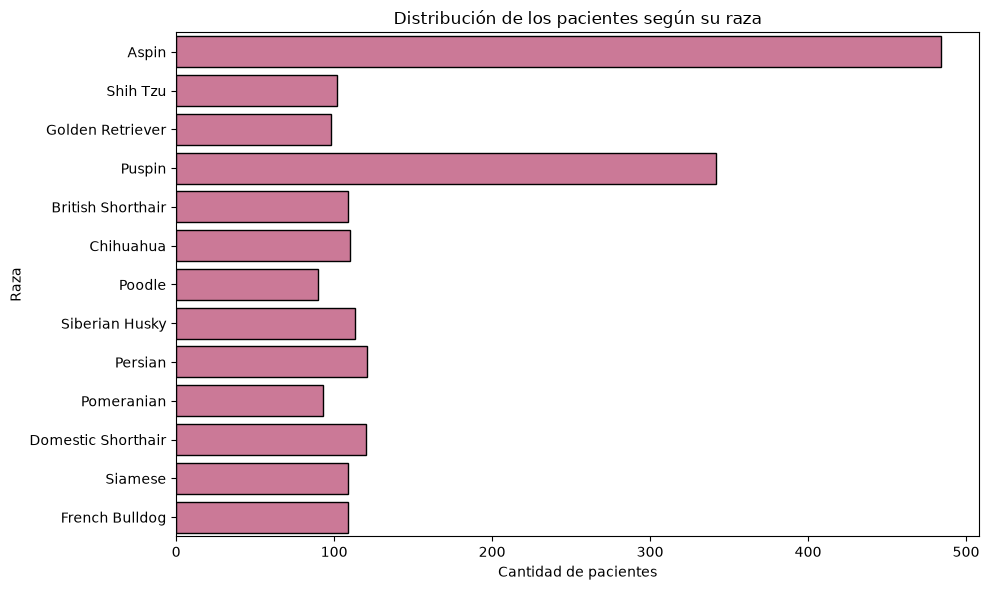

In [44]:
plot_razas_univariado(df)

Interpretacion: Se identifica que Aspin y Puspin son las categorías con mayor cantidad de pacientes, mientras que las demás razas presentan frecuencias relativamente similares y considerablemente menores.
Esto evidencia una distribución desigual de los pacientes según su raza, con una mayor representación de determinadas categorías dentro del dataset.

### Resultados de la lampara de Wood
Esta prueba se utiliza para la detección de determinadas infecciones fúngicas. Por este motivo, consideramos que puede resultar relevante para nuestro objetivo predictivo, especialmente al analizar las enfermedades de piel.
Utilizaremos un gráfico de barras para visualizar la cantidad de pacientes con resultados positivos y negativos.

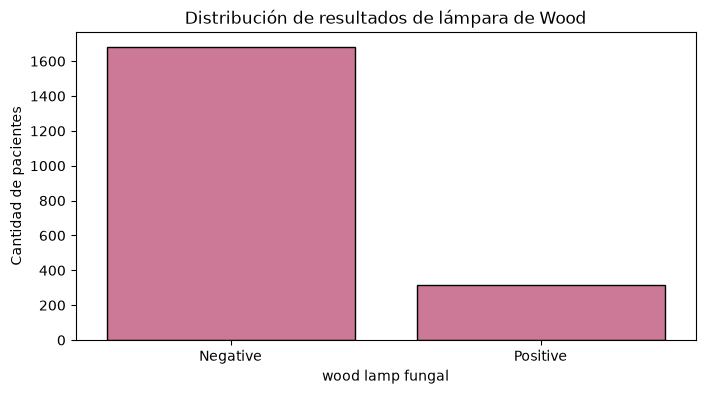

In [45]:

graficar_barras(df, 'wood lamp fungal',
                'Distribución de resultados de lámpara de Wood')


Interpretacion: El gráfico de barras muestra un claro predominio de resultados negativos en la prueba de lámpara de Wood, mientras que los resultados positivos representan una proporción considerablemente menor del conjunto de datos.
Esta distribución permite conocer la frecuencia de los resultados registrados. Sin embargo, un resultado negativo no implica necesariamente que el paciente esté sano o que no presente una enfermedad dermatológica.

## Analisis Bivariado
Una vez analizadas las variables de manera individual, continuaremos con un análisis bivariado para investigar las posibles relaciones entre distintas características de los pacientes.
El objetivo de esta etapa es identificar patrones que puedan resultar relevantes para el modelo predictivo.

### Relacion entre peso y frecuencia cardiaca
Analizamos la relación entre el peso y la frecuencia cardíaca de los pacientes veterinarios mediante un gráfico de dispersión (scatterplot).
Además, diferenciaremos a los pacientes según su especie, con el objetivo de observar posibles patrones entre caninos y felinos.

In [46]:

def plot_scatter_peso_frecuencia(df):
    '''
    Grafica la relación entre peso y frecuencia cardíaca,
    diferenciando a los pacientes según su especie.
    '''

    plt.figure(figsize=(10, 5))

    sns.scatterplot(data=df, x='weight', y='heart rate',
                    hue='species',
                    palette={'canine': '#d96b93',
                             'feline': '#e8a1be'})

    plt.title('Relación entre peso y frecuencia cardíaca')
    plt.xlabel('Peso (kg)')
    plt.ylabel('Frecuencia cardíaca (lpm)')

    plt.tight_layout()
    plt.show()


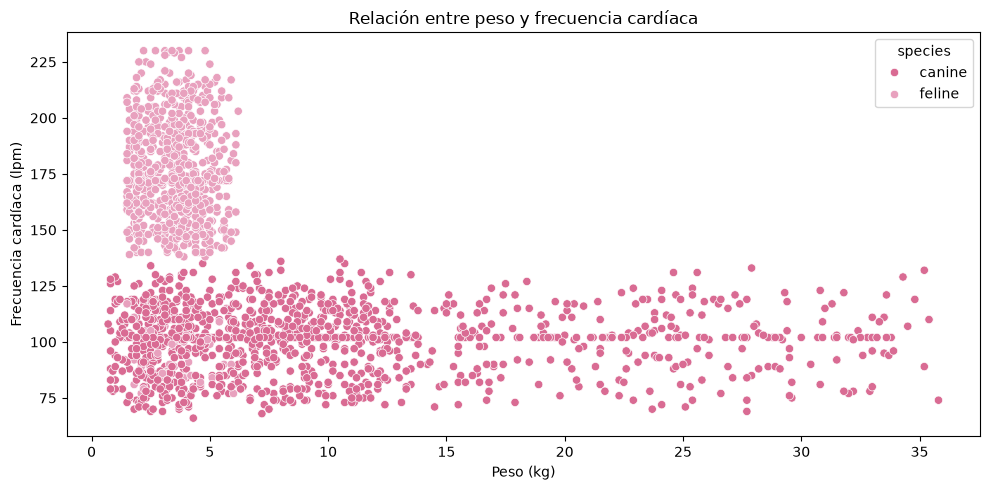

In [47]:
plot_scatter_peso_frecuencia(df)

Interpretación: Por un lado, los felinos presentan una distribución de peso más concentrada, principalmente entre los 2 y 6 kg. Sin embargo, sus frecuencias cardíacas se distribuyen en un intervalo relativamente amplio, la gran mayoría entre aproximadamente 140 y 230 latidos por minuto (lpm), con unos pocos pacientes en valores más bajos.
Por otro lado, los caninos presentan una mayor variabilidad en su peso, con valores que van desde aproximadamente 1 kg hasta superar los 35 kg. En cambio, sus frecuencias cardíacas se concentran mayormente entre 70 y 135 lpm.
Estas observaciones permiten identificar que los felinos presentan, en general, frecuencias cardíacas más elevadas que los caninos, a pesar de tener pesos menores. Esto sugiere que la especie podría ser un factor importante al analizar la relación entre ambas variables.
A partir de estos resultados surge una nueva pregunta: ¿las diferencias observadas en la frecuencia cardíaca responden a características propias de cada especie o podrían estar relacionadas con el estado de salud de los pacientes?

### Relacion entre la frecuencia cardiaca y el estado de salud
Analizaremos si existen diferencias en la frecuencia cardíaca entre pacientes sanos y enfermos, distinguiendo entre caninos y felinos.
Utilizaremos diagramas de boxplots para comparar las medianas, la dispersión y los rangos de frecuencia cardíaca de ambos grupos.
Esta comparación permitirá investigar si la frecuencia cardíaca presenta patrones asociados al estado de salud y si estos varían según la especie, con el objetivo de evaluar su posible utilidad para el modelo predictivo.

In [48]:
def plot_variable_estado(df, columna, titulo, etiqueta_y):
    '''
    Compara una variable numérica entre animales sanos
    y enfermos, diferenciando caninos y felinos.
    '''

    # Seleccionamos las columnas necesarias
    datos = df[['species', columna, 'estado_salud']].copy()

    plt.figure(figsize=(12, 5))

    # Boxplot de caninos
    plt.subplot(1, 2, 1)
    sns.boxplot(
        data=datos[datos['species'] == 'canine'],
        x='estado_salud',
        y=columna,
        order=['sano', 'enfermo'],
        color='#d96b93'
    )

    plt.title('Caninos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    # Boxplot de felinos
    plt.subplot(1, 2, 2)
    sns.boxplot(
        data=datos[datos['species'] == 'feline'],
        x='estado_salud',
        y=columna,
        order=['sano', 'enfermo'],
        color='#e8a1be'
    )

    plt.title('Felinos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    plt.suptitle(titulo, fontsize=14)

    plt.tight_layout()
    plt.show()


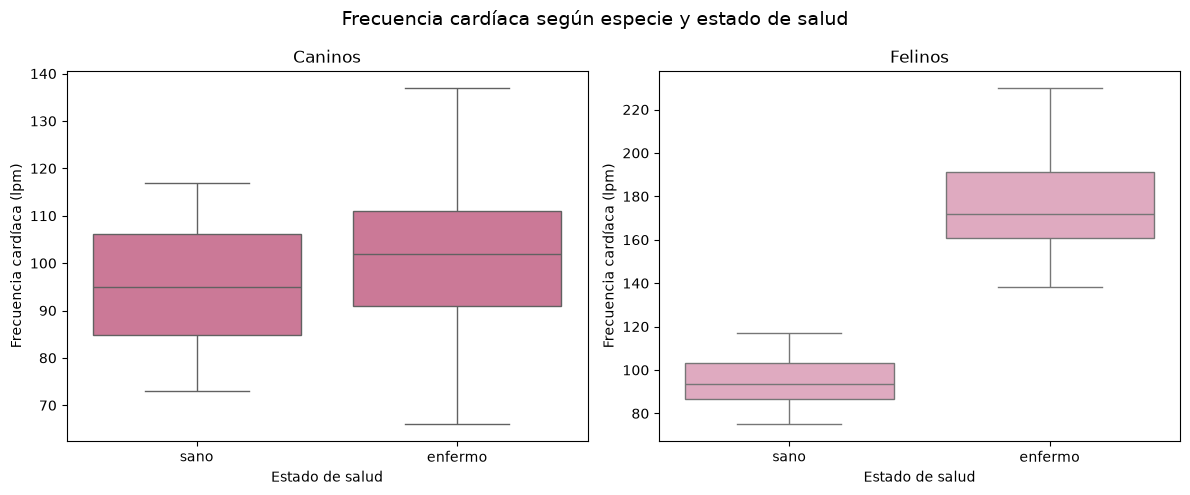

In [49]:
plot_variable_estado(
    df,
    'heart rate',
    'Frecuencia cardíaca según especie y estado de salud',
    'Frecuencia cardíaca (lpm)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones, lo que sugiere que la frecuencia cardíaca, por sí sola, podría no ser suficiente para distinguir ambos grupos.
En los felinos, se observa una diferencia mucho más marcada. Los pacientes clasificados como enfermos presentan frecuencias cardíacas considerablemente superiores a las de los sanos, sin que se observe superposición entre los rangos representados en el gráfico.
Estos resultados sugieren que la relación entre frecuencia cardíaca y estado de salud podría variar según la especie, por lo que ambas variables podrían ser relevantes para el modelo predictivo.

### Relacion entre la temperatura corporal y el estado de salud
Ahora analizamos la distribución de la temperatura corporal de los pacientes según su estado de salud, diferenciando entre caninos y felinos.
Reutilizaremos la función de boxplots definida anteriormente, que nos permitirá comparar las medianas y la dispersión de las temperaturas entre animales sanos y enfermos.
El objetivo es investigar si existen diferencias en la temperatura corporal asociadas al estado de salud y evaluar si esta variable podría aportar información relevante para el modelo predictivo.

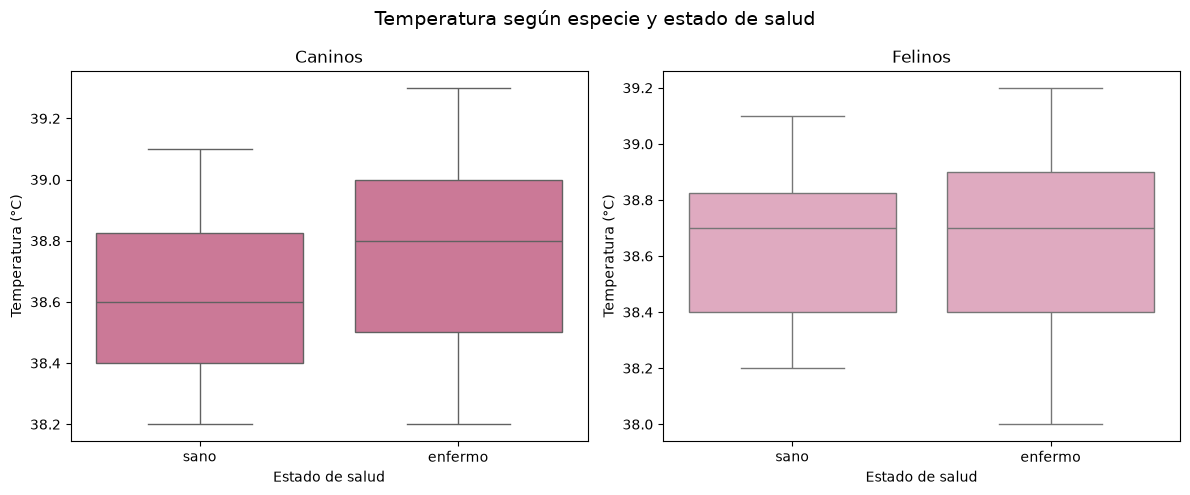

In [50]:
plot_variable_estado(
    df,
    'temperature',
    'Temperatura según especie y estado de salud',
    'Temperatura (°C)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones.
En los felinos, las medianas de los pacientes sanos y enfermos son prácticamente iguales, y sus distribuciones también presentan un importante solapamiento.
Estos resultados sugieren que la temperatura corporal, considerada de manera aislada, podría tener una utilidad limitada para distinguir animales sanos y enfermos dentro del conjunto de datos.
A diferencia de lo observado con la frecuencia cardíaca, especialmente en los felinos, la temperatura no presenta diferencias visualmente marcadas entre los estados de salud. Sin embargo, esto no significa que deba descartarse como variable predictora, ya que podría aportar información al combinarse con otras características de los pacientes.

### Relacion entre edad y el estado de salud 

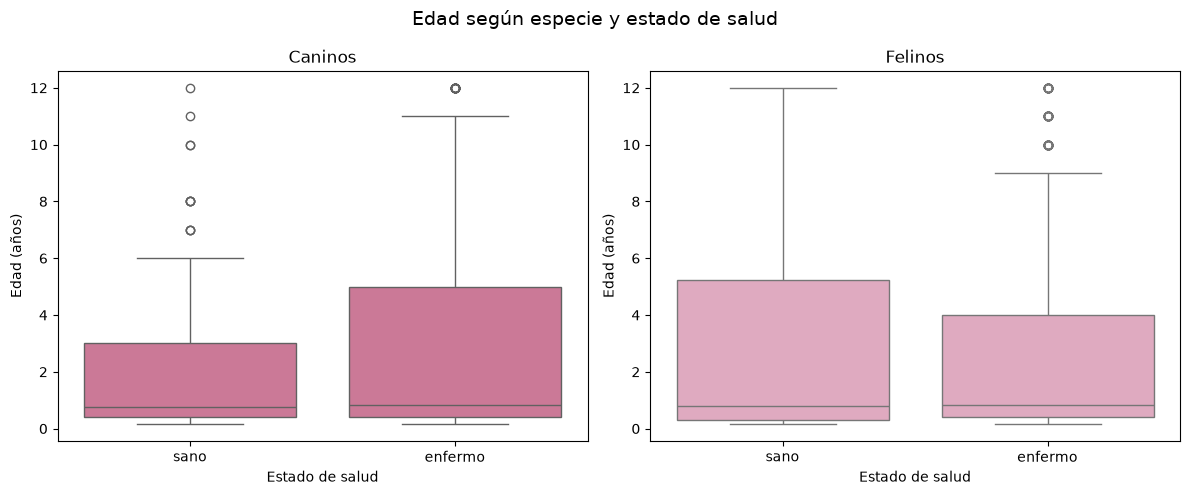

In [51]:
plot_variable_estado(
    df,
    'age',
    'Edad según especie y estado de salud',
    'Edad (años)'
)


Interpretacion: A partir de los boxplots, se observa que las medianas de edad de los pacientes sanos y enfermos son relativamente similares tanto en caninos como en felinos, aunque existen diferencias en la dispersión de sus distribuciones.
En los caninos, los pacientes enfermos presentan una mayor dispersión de edades dentro del 50 % central de las observaciones, mientras que los sanos muestran una distribución más concentrada en edades jóvenes. Además, se identifican posibles valores atípicos correspondientes a animales de mayor edad.
En los felinos, se observa una situación diferente: los pacientes sanos presentan una dispersión ligeramente mayor que los enfermos, aunque las medianas se mantienen próximas. También se identifican posibles valores atípicos en edades elevadas.
En ambos casos, las distribuciones presentan una superposición considerable, por lo que la edad, considerada de manera aislada, no parece permitir una diferenciación clara entre animales sanos y enfermos.

### Relación entre los resultados de la lámpara de Wood y el estado de salud
La lámpara de Wood es una prueba clínica utilizada para detectar determinadas infecciones fúngicas, por lo que resulta interesante explorar su relación con el estado de salud de los pacientes.
Mediante un gráfico de barras agrupadas, compararemos la frecuencia de resultados positivos y negativos entre animales sanos y enfermos, buscando identificar posibles asociaciones entre ambas variables.

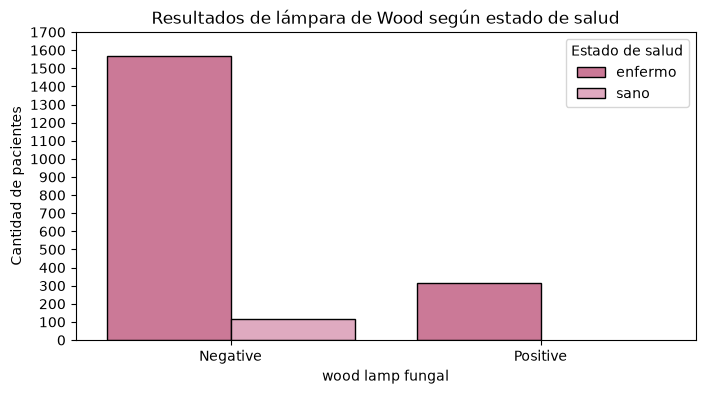

In [52]:
graficar_barras(
    df,
    'wood lamp fungal',
    'Resultados de lámpara de Wood según estado de salud',
    hue='estado_salud',
    paso_y=100,
    paleta={'enfermo': '#d96b93', 'sano': '#e8a1be'}
)



Interpretacion: Se identifica que todos los pacientes con resultado positivo aparecen clasificados como enfermos. Sin embargo, también se observa una cantidad considerable de animales enfermos entre aquellos que obtuvieron un resultado negativo.
Esto sugiere que un resultado positivo podría aportar información relevante para identificar determinados pacientes enfermos dentro del conjunto de datos, mientras que un resultado negativo no implica necesariamente que el animal esté sano.

### Relacion entre condición corporal según especie y estado de salud
La condición corporal es una característica que podría aportar información sobre el estado general de los pacientes veterinarios.
Aquí ompararemos las puntuaciones de condición corporal entre animales sanos y enfermos, distinguiendo entre caninos y felinos. Mediante diagramas de caja y bigotes, examinaremos si existen diferencias en las medianas y la dispersión de las puntuaciones, con el propósito de identificar posibles patrones asociados al estado de salud.

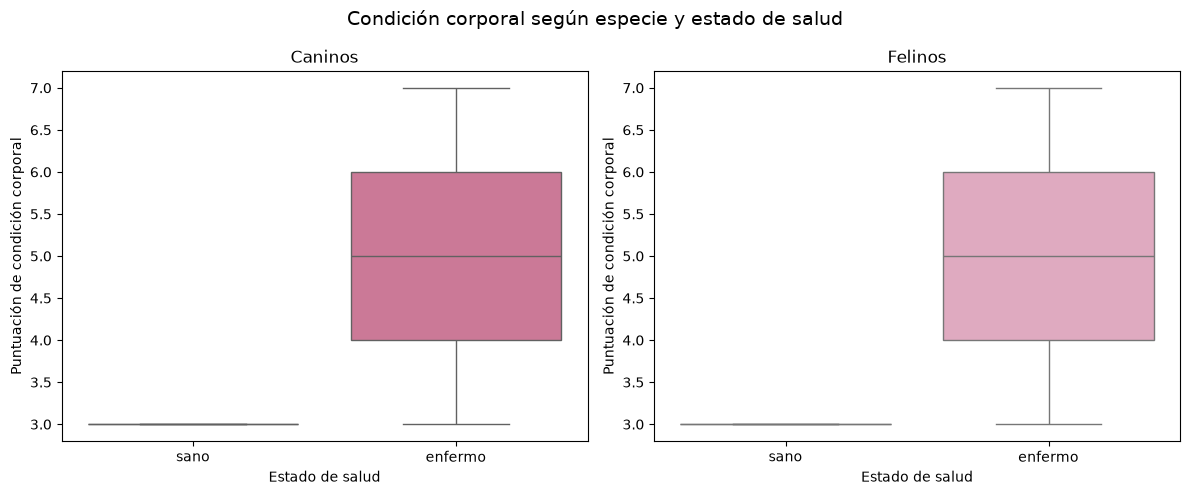

In [53]:

plot_variable_estado(
    df,
    'Body condition score',
    'Condición corporal según especie y estado de salud',
    'Puntuación de condición corporal'
)


Interpretacion: A partir de los boxplots, se observa una diferencia marcada en la distribución de las puntuaciones de condición corporal entre los pacientes sanos y enfermos.
Tanto en caninos como en felinos, los pacientes clasificados como sanos presentan una puntuación de condición corporal de 3, sin variabilidad visible.
En cambio, los pacientes enfermos presentan una mayor dispersión, con puntuaciones comprendidas entre 3 y 7 y una mediana cercana a 5 en ambas especies.
Estos resultados sugieren que la condición corporal podría aportar información relevante para distinguir el estado de salud de los pacientes. Sin embargo, una puntuación de 3 no garantiza que el animal esté sano, ya que también se registra entre los enfermos.

### Relación entre estado de salud y situcion de tenencia
La situación de tenencia de los pacientes es otra de las variables que consideramos relevante investigar, ya que podría presentar alguna asociación con su estado de salud.
Para explorar esta relación, utilizaremos un gráfico de barras agrupadas que nos permitirá comparar la cantidad de animales sanos y enfermos según su condición de tenencia: aquellos que tienen dueño (owned), los rescatados (rescued) y los registrados como perdidos y posteriormente rescatados (lost_rescued).

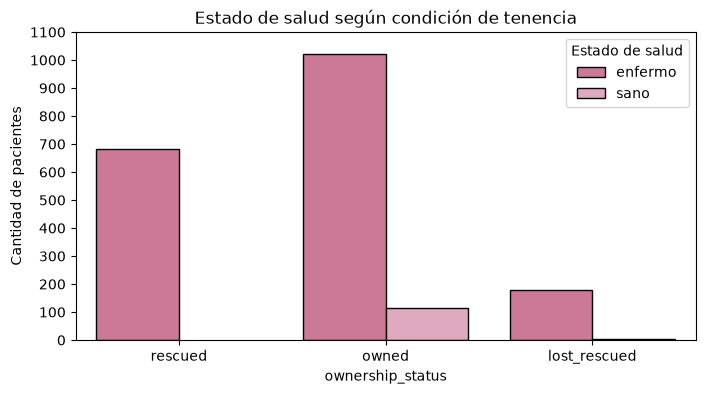

In [54]:

# Seleccionamos las columnas necesarias para el análisis
datos = df[['ownership_status', 'estado_salud']].copy()

# Graficamos el estado de salud según la condición de tenencia
graficar_barras(
    datos,
    'ownership_status',
    'Estado de salud según condición de tenencia',
    hue='estado_salud',
    paso_y=100,
    paleta={'enfermo': '#d96b93', 'sano': '#e8a1be'}
)


Interpretación: El gráfico de barras agrupadas permite observar la distribución de pacientes sanos y enfermos según su condición de tenencia.
Se identifica un predominio de pacientes enfermos en las tres categorías, siendo especialmente marcada esta diferencia en los animales rescatados y en aquellos registrados como lost_rescued.
Estos resultados plantean la posibilidad de una asociación entre la condición de tenencia y el estado de salud. Sin embargo, será necesario comparar las proporciones de pacientes enfermos dentro de cada grupo y verificar la consistencia de los datos antes de establecer conclusiones definitivas.

### Análisis de correlación entre variables numéricas
Ahora calculamos la matriz de correlaciones de Pearson entre las principales variables numéricas del dataset: peso, temperatura, frecuencia cardíaca, edad y condición corporal.
Posteriormente, representamos los coeficientes mediante un mapa de calor (heatmap) para facilitar la identificación de posibles relaciones lineales entre estas características clínicas.

In [55]:

# Seleccionamos las variables numéricas relevantes
variables_numericas = [
    'age',
    'weight',
    'temperature',
    'heart rate',
    'Body condition score'
]

# Calculamos la matriz de correlaciones
corr_matrix = df[variables_numericas].corr()

corr_matrix


,age,weight,temperature,heart rate,Body condition score
age,1.000000,0.149847,-0.007351,0.001839,0.036794
weight,0.149847,1.000000,0.062153,-0.391170,0.008476
temperature,-0.007351,0.062153,1.000000,-0.117453,-0.006544
heart rate,0.001839,-0.391170,-0.117453,1.000000,0.097506
Body condition score,0.036794,0.008476,-0.006544,0.097506,1.000000


In [56]:

def plot_mapa_calor(corr_matrix):
    '''
    Grafica el mapa de calor de las correlaciones
    entre variables numéricas.
    '''

    plt.figure(figsize=(8, 6))

    sns.heatmap(corr_matrix, annot=True, cmap='RdPu',
                vmin=-1, vmax=1, fmt='.2f')

    plt.title('Mapa de calor de correlaciones')

    plt.tight_layout()
    plt.show()


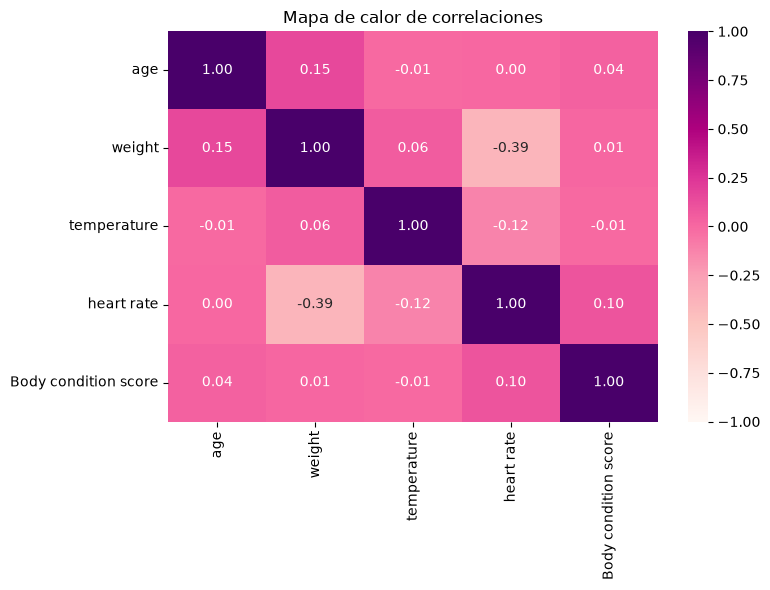

In [57]:
plot_mapa_calor(corr_matrix)

Interpretacion: A partir de la matriz de correlaciones de Pearson, se observa que la mayoría de las variables numéricas presentan asociaciones lineales muy débiles o prácticamente nulas.
La relación más destacada corresponde al peso y la frecuencia cardíaca, con un coeficiente aproximado de −0,345, lo que indica una correlación negativa débil. Esto sugiere que, dentro del conjunto de datos, los pacientes de mayor peso tienden a presentar frecuencias cardíacas menores.
Sin embargo, esta relación podría estar influida por las diferencias entre especies, ya que anteriormente observamos que los felinos presentan, en general, pesos menores y frecuencias cardíacas superiores a las de los caninos.
Por otro lado, la edad presenta correlaciones muy bajas con las demás variables numéricas. Su asociación más elevada corresponde al peso (r ≈ 0,15), mientras que con la temperatura, la frecuencia cardíaca y la condición corporal los coeficientes son cercanos a cero.
En general, no se identifican correlaciones lineales fuertes entre las características numéricas analizadas.

# Agrupaciones y Visualizaciones:
En esta primera etapa de análisis bivariado, nos propusimos agrupar y clasificar los diagnósticos definitivos de los pacientes para examinar la frecuencia de las principales patologías en función de la especie. El objetivo de este procedimiento es identificar la distribución global de las afecciones clínicas en el dataset, permitiendo visualizar qué tipo de patologías predominan tanto en caninos como en felinos antes de profundizar en las pruebas de laboratorio específicas.
Más abajo se presentarán tres ejes analíticos fundamentales: en primer lugar, el cruce entre la condición de tenencia y el estado de salud general de los pacientes; en segundo término, la evaluación del rendimiento de la prueba de la lámpara de Wood frente a las patologías cutáneas; y por último, el estudio comparativo de las constantes fisiológicas de frecuencia cardíaca segmentadas por especie y condición clínica.

In [58]:
# 1. Función para agrupar los diagnósticos según el objetivo del modelo
def clasificar_patologia(diag):
  if diag == 'healthy':
    return 'Sano'

  es_piel = any(term in diag for term in ['Dermatitis', 'Ringworm'])
  es_otico = any(term in diag for term in ['Otitis', 'Ear Mites'])

  if es_piel and es_otico:
    return 'Piel y Ótico (Mixto)'
  elif es_piel:
    return 'Afección de Piel'
  elif es_otico:
    return 'Afección Ótica'
  else:
    return 'Otro'


df['categoria_diagnostico'] = df['definitive diagnosis'].apply(
    clasificar_patologia
)

# 2. groupby + agg para calcular métricas por especie y categoría
df_agrupado = (
    df.groupby(['species', 'categoria_diagnostico'])
    .agg(
        cantidad_pacientes=('species', 'count'),
        peso_promedio=('weight', 'mean'),
    )
    .reset_index()
)

print('Resultado de la agregación (groupby + agg):')
display(df_agrupado)

Resultado de la agregación (groupby + agg):


,species,categoria_diagnostico,cantidad_pacientes,peso_promedio
0,canine,Afección de Piel,363,9.956198
1,canine,Afección Ótica,389,10.648072
2,canine,Piel y Ótico (Mixto),375,10.637333
3,canine,Sano,72,10.075000
4,feline,Afección de Piel,268,3.555970
5,feline,Afección Ótica,255,3.521961
6,feline,Piel y Ótico (Mixto),234,3.555556
7,feline,Sano,44,3.422727


#### Gráfico de distribución de diagnósticos:

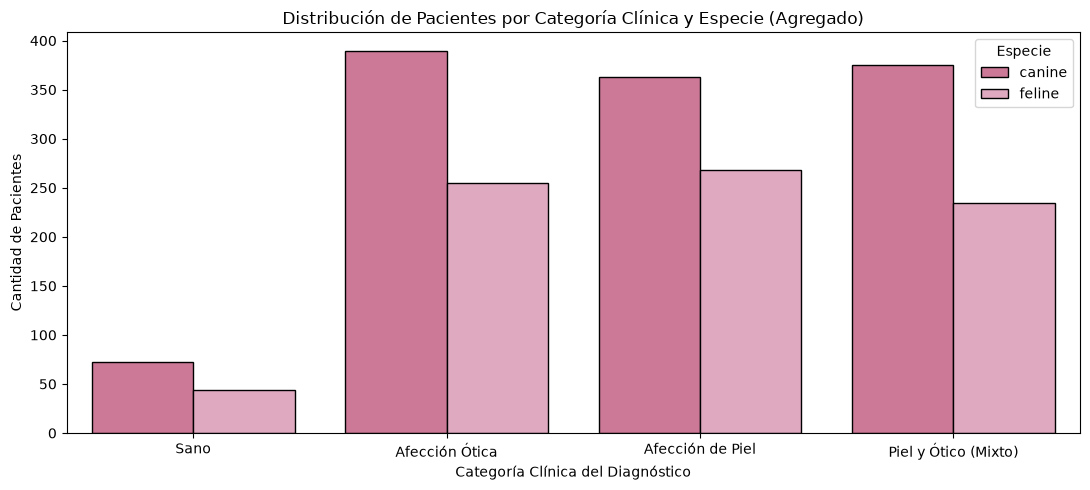

In [59]:
# 3. Barplot basado en la agregación para ver el cruce de variables útil
plt.figure(figsize=(11, 5))
sns.barplot(
    data= df_agrupado,
    x='categoria_diagnostico',
    y='cantidad_pacientes',
    hue='species',
    order=['Sano', 'Afección Ótica', 'Afección de Piel', 'Piel y Ótico (Mixto)'],
    palette={'canine': '#d96b93', 'feline': '#e8a1be'},
    edgecolor='black',
)

plt.title(
    'Distribución de Pacientes por Categoría Clínica y Especie (Agregado)',
    fontsize=12,
)
plt.xlabel('Categoría Clínica del Diagnóstico', fontsize=10)
plt.ylabel('Cantidad de Pacientes', fontsize=10)
plt.legend(title='Especie')
plt.tight_layout()
plt.show()

### Interpretación de Hallazgos y Análisis del Modelo Predictivo
 Tras agrupar los diagnósticos definitivos según el objetivo del modelo, vemos que las tres categorías de enfermedad tienen volúmenes similares: Afección Ótica (644 pacientes: 389 caninos y 255 felinos), Afección de Piel (631: 363 y 268) y casos Mixtos de Piel y Ótico (609: 375 y 234). Los pacientes sanos son una minoría (116: 72 caninos y 44 felinos, un 5,8 % del total).

Los caninos concentran más casos que los felinos en todas las categorías (el dataset tiene un 60 % de caninos) y la proporción entre patologías es parecida en ambas especies. Esto tiene una consecuencia para el modelo: como las tres afecciones están casi igual de representadas no hay una clase dominante, mientras que la clase Sano es muy pequeña.

### Justificación sobre la Serie Temporal:
¿Es posible armar una serie temporal? No para los fines analíticos del modelo predictivo.

Motivo: 
Una serie temporal busca proyectar eventos en el tiempo (tendencias o estacionalidades futuras), lo cual no aporta valor ni guarda relación biológica con el objetivo central del programa. El propósito de nuestro modelo de clasificación (KNN) es predecir el estado de salud y la patología clínica (ótica, de piel o mixta) en función de las características biométricas y signos vitales del paciente al momento de la consulta. Por lo tanto, el enfoque temporal se omite del modelado por una decisión estrictamente analítica y de diseño del algoritmo, priorizando por completo el perfil clínico de los animales.

## Análisis de Variables Clínicas, Demográficas y Pruebas de Apoyo en la Población Veterinaria
### Análisis Bivariado: Proporción del Estado de Salud según el Origen del Animal
En el análisis exploratorio identificamos diferencias en la cantidad de pacientes sanos y enfermos
según su situación de tenencia.
Sin embargo, como las categorías presentan distintos tamaños, las frecuencias absolutas no permiten comparar directamente el peso de cada estado de salud dentro de los grupos.
Por este motivo, calcularemos la proporción de animales sanos y enfermos en cada categoría de tenencia y la representaremos mediante un gráfico de barras apiladas al 100 %.

In [60]:
if 'estado_salud' not in df.columns:
    df['estado_salud'] = df['definitive diagnosis'].apply(lambda x: 'sano' if x == 'healthy' else 'enfermo')

# Agrupación por ownership_status y estado_salud usando .size() 
resumen_tenencia = df.groupby(['ownership_status', 'estado_salud']).size().reset_index(name='cantidad_pacientes')

# Calculamos el total por cada grupo de tenencia para sacar el porcentaje
total_por_tenencia = df.groupby('ownership_status').size().reset_index(name='total_grupo')
resumen_tenencia = resumen_tenencia.merge(total_por_tenencia, on='ownership_status')
resumen_tenencia['porcentaje'] = (resumen_tenencia['cantidad_pacientes'] / resumen_tenencia['total_grupo']) * 100

display(resumen_tenencia)

,ownership_status,estado_salud,cantidad_pacientes,total_grupo,porcentaje
0,lost_rescued,enfermo,179,182,98.351648
1,lost_rescued,sano,3,182,1.648352
2,owned,enfermo,1021,1134,90.035273
3,owned,sano,113,1134,9.964727
4,rescued,enfermo,684,684,100.000000


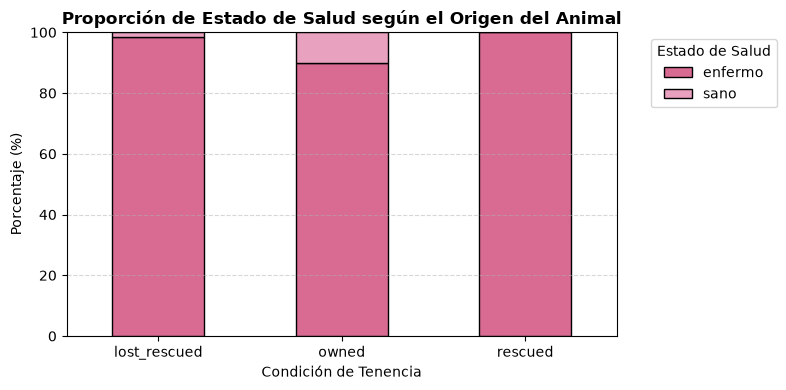

In [61]:
# Gráfico de barras 100% apilado para visualizar la proporción de sanos/enfermos por tenencia
cross_tenencia = pd.crosstab(df['ownership_status'], df['estado_salud'], normalize='index') * 100

cross_tenencia.plot(kind='bar', stacked=True, color=['#d96b93', '#e8a1be'], edgecolor='black', figsize=(8, 4))
plt.title('Proporción de Estado de Salud según el Origen del Animal', fontsize=12, fontweight='bold')
plt.xlabel('Condición de Tenencia', fontsize=10)
plt.ylabel('Porcentaje (%)', fontsize=10)
plt.legend(title='Estado de Salud', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
A diferencia de los recuentos absolutos previos, normalizar las proporciones dentro de cada categoría de tenencia permite neutralizar la diferencia de tamaño entre los grupos (ya que existen más animales con dueño que rescatados), evidenciando de forma equitativa que los animales con dueño concentran una pequeña proporción de casos catalogados como sanos (cerca del 10%), mientras que en los grupos de animales rescatados y perdidos la gran mayoría de los ingresos se registran bajo cuadros de enfermedad. Esto demuestra que la condición de tenencia actúa como un indicador contextual fuerte y un criterio descriptivo sumamente útil para respaldar el comportamiento de la salud de los pacientes en el modelo predictivo.

### Evaluación de la Prueba Diagnóstica de Lámpara de Wood según las Patologías Cutáneas y Óticas
En esta instancia del análisis exploratorio, nos propusimos cruzar los resultados de la prueba de la lámpara de Wood con los principales tipos de afecciones de los pacientes enfermos. Este procedimiento se realizó con el fin de examinar el rendimiento y la especificidad de dicha prueba diagnóstica, evaluando si actúa como un indicador clínico diferencial confiable para respaldar al modelo predictivo en la distinción de patologías cutáneas frente a cuadros óticos. Mientras que en las secciones previas se evaluó el test de forma global, en este apartado profundizamos específicamente en la población de pacientes enfermos para analizar las particularidades de esta prueba en relación exclusiva con las patologías cutáneas y mixtas.

In [62]:
# Filtramos solo los pacientes enfermos y clasificamos la afección principal
enfermos = df[df['estado_salud'] == 'enfermo'].copy()

def clasificar_afeccion(diag):
    diag_lower = diag.lower()
    tiene_piel = 'dermatitis' in diag_lower or 'ringworm' in diag_lower
    tiene_otitis = 'otitis' in diag_lower or 'mites' in diag_lower
    
    if tiene_piel and tiene_otitis:
        return 'Ambas (Piel y Otitis)'
    elif tiene_piel:
        return 'Enfermedad de Piel'
    elif tiene_otitis:
        return 'Otitis'
    else:
        return 'Otro'

enfermos['tipo_afeccion'] = enfermos['definitive diagnosis'].apply(clasificar_afeccion)

# Agrupamos por tipo de afección y resultado de la lámpara de Wood
resumen_lampara = enfermos.groupby(['tipo_afeccion', 'wood lamp fungal']).size().reset_index(name='cantidad')

# Calculamos porcentajes dentro de cada tipo de afeccion
total_afecion = enfermos.groupby('tipo_afeccion').size().reset_index(name='total_afecion')
resumen_lampara = resumen_lampara.merge(total_afecion, on='tipo_afeccion')
resumen_lampara['porcentaje'] = (resumen_lampara['cantidad'] / resumen_lampara['total_afecion']) * 100

display(resumen_lampara)

,tipo_afeccion,wood lamp fungal,cantidad,total_afecion,porcentaje
0,Ambas (Piel y Otitis),Negative,433,609,71.100164
1,Ambas (Piel y Otitis),Positive,176,609,28.899836
2,Enfermedad de Piel,Negative,490,631,77.654517
3,Enfermedad de Piel,Positive,141,631,22.345483
4,Otitis,Negative,644,644,100.000000


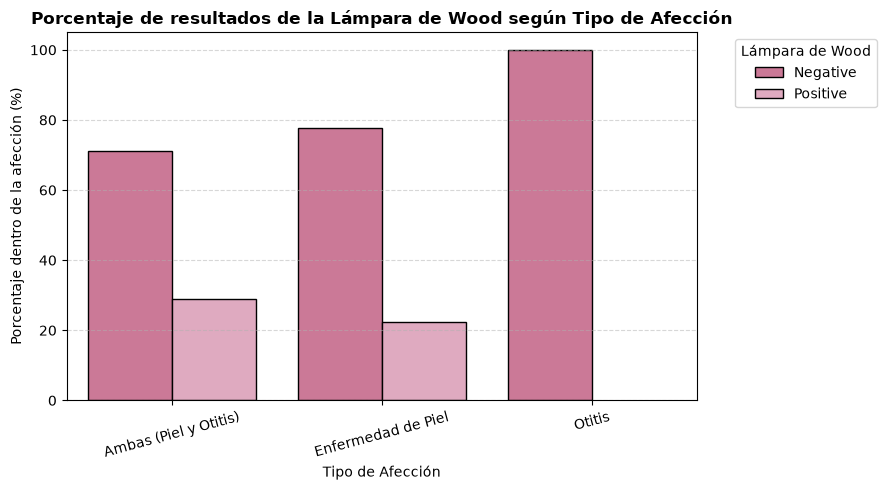

In [63]:
# Gráfico para visualizar los resultados de la lámpara de Wood según el tipo de afección
plt.figure(figsize=(9, 5))
sns.barplot(
    data=resumen_lampara, 
    x='tipo_afeccion', 
    y='porcentaje', 
    hue='wood lamp fungal', 
    palette=['#d96b93', '#e8a1be'], 
    edgecolor='black'
)

plt.title('Porcentaje de resultados de la Lámpara de Wood según Tipo de Afección', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Afección', fontsize=10)
plt.ylabel('Porcentaje dentro de la afección (%)', fontsize=10)
plt.legend(title='Lámpara de Wood', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
El gráfico expone de manera categórica que los resultados positivos de la lámpara de Wood se concentran exclusivamente en las patologías que involucran la piel (enfermedades cutáneas y cuadros mixtos), arrojando un 100% de negativos en pacientes con afecciones exclusivamente óticas. Esto demuestra que un resultado positivo funciona como un fuerte indicador de afección cutánea, mientras que el resultado negativo requiere complementarse con otras variables. De este modo, la clara segmentación confirma que la variable posee un gran valor clínico y aporta una base útil para que el algoritmo k-NN logre clasificar las patologías sin generar ruido innecesario.

### Análisis Multivariado: Distribución de la Frecuencia Cardíaca según Especie y Estado de Salud
En esta parte del análisis exploratorio, agrupamos y analizamos la frecuencia cardíaca de los pacientes dividiéndola por especie y estado de salud. Este procedimiento se realizó con el objetivo de identificar patrones fisiológicos diferenciales y comprobar cómo varían los signos vitales entre caninos y felinos, respaldando de forma empírica la decisión técnica de realizar una imputación de nulos segmentada para este parámetro clínico. Complementando la exploración visual de las distribuciones de signos vitales, formalizamos a continuación un resumen estadístico desagregado (mediana, mínimos y máximos) para dimensionar con precisión la dispersión y el rango fisiológico de los latidos por minuto en cada subgrupo de pacientes.

In [64]:
# Agrupación por especie y estado de salud calculando estadísticas de heart rate
resumen_hr = df.groupby(['species', 'estado_salud']).agg(
    cantidad_pacientes=('species', 'count'),
    mediana_hr=('heart rate', 'median'),
    min_hr=('heart rate', 'min'),
    max_hr=('heart rate', 'max')
).reset_index()

display(resumen_hr)

,species,estado_salud,cantidad_pacientes,mediana_hr,min_hr,max_hr
0,canine,enfermo,1127,102.0,66.0,137.0
1,canine,sano,72,95.0,73.0,117.0
2,feline,enfermo,757,172.0,138.0,230.0
3,feline,sano,44,93.5,75.0,117.0


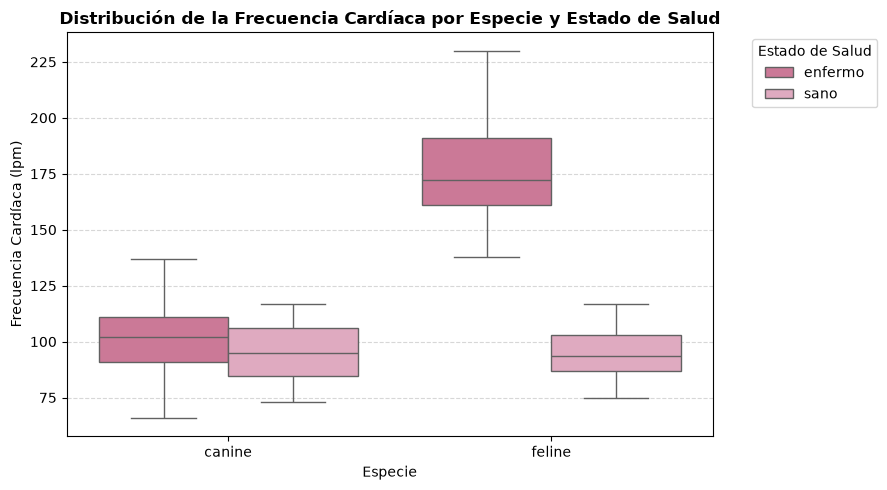

In [65]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, 
    x='species', 
    y='heart rate', 
    hue='estado_salud', 
    palette=['#d96b93', '#e8a1be']
)

plt.title('Distribución de la Frecuencia Cardíaca por Especie y Estado de Salud', fontsize=12, fontweight='bold')
plt.xlabel('Especie', fontsize=10)
plt.ylabel('Frecuencia Cardíaca (lpm)', fontsize=10)
plt.legend(title='Estado de Salud', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
Los felinos tienen frecuencias cardíacas claramente más altas que los caninos. Dentro de los felinos, los sanos tienen valores bajos y los enfermos valores altos, sin superposición visible en el gráfico; en los caninos las distribuciones de sanos y enfermos se solapan. Por eso la frecuencia cardíaca es una variable muy útil para el modelo de estado de salud, pero debe interpretarse junto con la especie (ambas entran como predictoras). Como KNN se basa en distancias, escalamos las variables con `StandardScaler` dentro del Pipeline.

## Modelo de clasificación con K-Nearest Neighbors (KNN)

### Definición del objetivo

El objetivo del proyecto es realizar dos predicciones consecutivas:

1. **Primer modelo:** determinar si el paciente está sano o enfermo.
2. **Segundo modelo:** solamente para los pacientes clasificados como enfermos, identificar si la afección es de piel, de oído o mixta (piel y oído).

De esta manera, no intentamos predecir directamente todas las categorías en un único paso, sino que organizamos la clasificación de acuerdo con el objetivo del proyecto.

La categoría **Mixto** es necesaria porque algunos diagnósticos originales incluyen al mismo tiempo una afección de piel y una afección de oído.

In [66]:
# Observamos las categorías que utilizaremos en cada etapa
print("Estado de salud:")
display(df["estado_salud"].value_counts())

print("\nCategoría del diagnóstico:")
display(df["categoria_diagnostico"].value_counts())

Estado de salud:


estado_salud
enfermo    1884
sano        116
Name: count, dtype: int64


Categoría del diagnóstico:


categoria_diagnostico
Afección Ótica          644
Afección de Piel        631
Piel y Ótico (Mixto)    609
Sano                    116
Name: count, dtype: int64

## Primer modelo (etapa 1): ¿el paciente está sano o enfermo?

### ¿Cómo funciona k-NN?
1. Para un paciente nuevo, el modelo busca los **k pacientes más parecidos** del conjunto de entrenamiento (los "vecinos", medidos por distancia entre sus variables).
2. Cada vecino **vota** por su categoría.
3. La predicción es la categoría **más votada**.

No "aprende" ninguna fórmula: guarda los datos de entrenamiento y los consulta. Por eso dos cosas son críticas: **la escala de las variables** (porque mide distancias) y **el valor de k**.

### Definir X e y

- **y (lo que queremos predecir):** `estado_salud` (`Sano` / `Enfermo`).
- **X (con qué lo predecimos):** edad, peso, temperatura, frecuencia cardíaca, condición corporal, especie, sexo y resultado de la lámpara de Wood. k-NN necesita números, así que las tres categóricas (que tienen 2 valores) las pasamos a 0/1.

In [67]:
X = df[["age", "weight", "temperature", "heart rate", "Body condition score"]].copy()
X["es_perro"] = (df["species"] == "canine").astype(int)
X["es_macho"] = (df["sex"] == "male").astype(int)
X["wood_positiva"] = (df["wood lamp fungal"] == "Positive").astype(int)

y = df["estado_salud"].map({"sano": "Sano", "enfermo": "Enfermo"})

print("X:", X.shape, "| y:", y.shape)
X.head()

X: (2000, 8) | y: (2000,)


,age,weight,temperature,heart rate,Body condition score,es_perro,es_macho,wood_positiva
0,4.000000,6.7,39.1,114.0,4.0,1,1,0
1,9.000000,9.7,39.1,102.0,4.0,1,1,0
2,0.230769,11.7,39.1,102.0,3.0,1,1,0
3,12.000000,4.1,38.7,172.0,3.0,0,0,0
4,3.000000,8.1,39.0,79.0,3.0,1,0,0


### Separar train y test (con `stratify`)

80 % para entrenar y 20 % para evaluar. Usamos `stratify=y` para que train y test tengan **la misma proporción de sanos y enfermos** (con solo 5,8 % de sanos es importante: sin `stratify` el test podría quedar con muy pocos).

In [68]:
SEMILLA = 42   # semilla para que los resultados se puedan reproducir

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)

Train: (1600, 8)  Test: (400, 8)


,train,test
estado_salud,,
Enfermo,0.942,0.942
Sano,0.058,0.058


### El baseline: predecir siempre la clase más frecuente

In [69]:
orden = ["Sano", "Enfermo"]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

acc_baseline = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline (siempre '{baseline.predict(X_test)[0]}'): {acc_baseline:.1%}")

Baseline (siempre 'Enfermo'): 94.2%


**Este baseline es muy exigente.** Como el 94 % de los pacientes está enfermo, un "modelo" que responde siempre *Enfermo* ya acierta el 94 %... y **nunca detecta un solo paciente sano**. Por eso el accuracy solo no alcanza: vamos a mirar también la matriz de confusión y el `classification_report`.

### k-NN con k=5 (sin escalar)

In [70]:
knn_crudo = KNeighborsClassifier(n_neighbors=5)
knn_crudo.fit(X_train, y_train)
y_pred = knn_crudo.predict(X_test)

print(f"Baseline:  {acc_baseline:.1%}")
print(f"k-NN k=5:  {accuracy_score(y_test, y_pred):.1%}")

Baseline:  94.2%
k-NN k=5:  94.0%


Antes de ver más resultados, un problema: **las variables están en escalas muy distintas**. k-NN mide distancias, así que una variable con números grandes pesa más que una con números chicos, solamente por la unidad en la que se mide.

In [71]:
# Rango de cada columna de X (en train)
X_train.describe().loc[["min", "max"]].T

,min,max
age,0.153846,12.0
weight,0.700000,35.8
temperature,38.000000,39.3
heart rate,66.000000,230.0
Body condition score,3.000000,7.0
es_perro,0.000000,1.0
es_macho,0.000000,1.0
wood_positiva,0.000000,1.0


La frecuencia cardíaca (de ~50 a ~250) y el peso (hasta ~40) dominarían la distancia, mientras que las columnas 0/1 (especie, sexo, lámpara de Wood) casi no contarían, aunque la lámpara de Wood sea muy informativa. La solución es la de la Unidad 7: **`StandardScaler`** (lleva cada columna a media 0 y desvío 1) dentro de un **`Pipeline`**, para que el escalado se calcule solo con los datos de train y se aplique igual a test.

In [72]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Enfermo','Sano']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['age','weight','temperature',...,'es_perro','es_macho','wood_positiva']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### ¿Escalar mejora? Lo decidimos con validación cruzada (sin mirar el test)

Para comparar dos modelos **no usamos el test**: usamos validación cruzada dentro de train. Con `StratifiedKFold` partimos train en 5 partes que mantienen la proporción de sanos y enfermos (`shuffle=True` porque el CSV no está en orden aleatorio): se entrena con 4 partes y se evalúa con la restante, 5 veces.

In [73]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

cv_crudo = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train, y_train, cv=kfold, scoring="accuracy")
cv_escalado = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="accuracy")

print(f"k-NN sin escalar (k=5): {cv_crudo.mean():.1%} ± {cv_crudo.std():.1%}")
print(f"k-NN escalado    (k=5): {cv_escalado.mean():.1%} ± {cv_escalado.std():.1%}")

k-NN sin escalar (k=5): 93.3% ± 0.9%
k-NN escalado    (k=5): 95.4% ± 0.6%


### Ver cómo vota k-NN: los 5 vecinos de un paciente

In [74]:
# Tomamos un paciente de test y buscamos sus 5 vecinos más cercanos (en el espacio escalado)
i = 0
paciente = X_test.iloc[[i]]
distancias, posiciones = pipe.named_steps["knn"].kneighbors(pipe.named_steps["scaler"].transform(paciente))

vecinos = X_train.iloc[posiciones[0]].copy()
vecinos["estado_salud"] = y_train.iloc[posiciones[0]].values
vecinos["distancia"] = distancias[0].round(2)

print(f"Paciente de test · real: {y_test.iloc[i]} · predicción: {pipe.predict(paciente)[0]}")
vecinos

Paciente de test · real: Enfermo · predicción: Enfermo


,age,weight,temperature,heart rate,Body condition score,es_perro,es_macho,wood_positiva,estado_salud,distancia
411,6.0,2.4,39.0,86.0,5.0,1,1,0,Enfermo,0.55
694,7.0,7.5,39.0,102.0,5.0,1,1,0,Enfermo,0.69
1714,4.0,3.2,39.0,110.0,5.0,1,1,0,Enfermo,0.70
1790,8.0,2.3,38.8,121.0,5.0,1,1,0,Enfermo,0.84
295,8.0,2.3,38.9,105.0,6.0,1,1,0,Enfermo,0.94


Cada fila es un vecino del paciente: se ve cuán parecido es (`distancia`) y qué estado tiene. La predicción sale de la **votación** entre estas 5 filas.

### Elegir k con `GridSearchCV`

**k no se elige mirando el test.** `GridSearchCV` prueba muchos valores de k, cada uno con validación cruzada dentro de train, y se queda con el mejor. La grilla es la de la Unidad 7 (de k=1 hasta k=400): con k muy chico el modelo "memoriza" (sobreajuste) y con k muy grande vota siempre por la clase mayoritaria.

In [75]:
grilla = {"knn__n_neighbors": [1, 5, 15, 50, 100, 200, 400]}

busqueda = GridSearchCV(pipe, grilla, cv=kfold, scoring="accuracy")
busqueda.fit(X_train, y_train)   # 7 valores de k x 5 rondas = 35 modelos

print("Mejor k:", busqueda.best_params_)
print(f"Accuracy de validación: {busqueda.best_score_:.1%}")

Mejor k: {'knn__n_neighbors': 5}
Accuracy de validación: 95.4%


### Evaluación final en test (una sola vez)
Una vez encontrado el mejor hiperparámetro $k$ mediante validación cruzada en el conjunto de entrenamiento, evaluamos el modelo final una única vez sobre el conjunto de test para medir su rendimiento real frente al baseline.

Baseline:  94.2%
k-NN (k=5): 95.0%
Aciertos: 380 de 400


,pred Sano,pred Enfermo
real Sano,11,12
real Enfermo,8,369


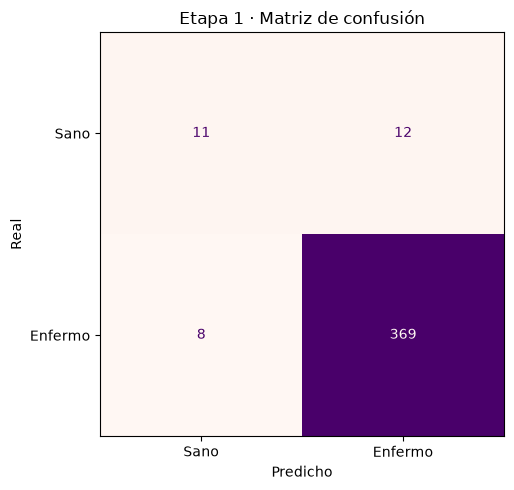

              precision    recall  f1-score   support

        Sano      0.579     0.478     0.524        23
     Enfermo      0.969     0.979     0.974       377

    accuracy                          0.950       400
   macro avg      0.774     0.729     0.749       400
weighted avg      0.946     0.950     0.948       400



In [76]:
mejor_knn = busqueda.best_estimator_      # ya reentrenado con todo train
y_pred_final = mejor_knn.predict(X_test)

print(f"Baseline:  {acc_baseline:.1%}")
print(f"k-NN (k={busqueda.best_params_['knn__n_neighbors']}): {accuracy_score(y_test, y_pred_final):.1%}")
print(f"Aciertos: {(y_test == y_pred_final).sum()} de {len(y_test)}")

# Matriz de confusión (filas = real, columnas = predicho)
cm = confusion_matrix(y_test, y_pred_final, labels=orden)
display(pd.DataFrame(cm, index=[f"real {c}" for c in orden], columns=[f"pred {c}" for c in orden]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, labels=orden, ax=ax, cmap="RdPu", colorbar=False)
ax.set_title("Etapa 1 · Matriz de confusión")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_final, labels=orden, digits=3))

**Resultado de la etapa 1 (test, 400 pacientes; k = 5):**
- **Accuracy:** KNN 95,0 % contra baseline 94,2 % (+3 pacientes): la mejora es **marginal**.
- **Sanos:** detecta 11 de 23 (recall 48 %, precision 58 %); el baseline no detecta ninguno.
- **Enfermos:** recall 98 %, pero deja pasar **8 enfermos como sanos**.
- **¿En qué se equivoca?** Un enfermo con condición corporal 3 (la de todos los sanos), temperatura normal y lámpara negativa es casi idéntico a un sano, y con estas variables el KNN no puede diferenciarlos.



## Segundo modelo (etapa 2): ¿qué tipo de afección tiene?

Esta etapa se aplica **solo a pacientes enfermos** y distingue tres clases: **Afección de Piel**, **Afección Ótica** y **Piel y Ótico (Mixto)**. Los sanos no participan porque ya se descartaron en la etapa 1.

Repetimos exactamente el mismo flujo de la etapa 1. Para no mezclar datos, usamos **la misma separación train/test** de la etapa 1 y nos quedamos solo con los pacientes enfermos de cada una: así ningún paciente de test de la etapa 1 pasó por el entrenamiento de la etapa 2.

### Definir X e y, y separar train/test

In [77]:
# Pacientes enfermos de train y de test (usando las particiones de la etapa 1)
X2_train = X_train[y_train == "Enfermo"]
X2_test = X_test[y_test == "Enfermo"]

# Nueva variable objetivo: tipo de afección
y2_train = df.loc[X2_train.index, "categoria_diagnostico"]
y2_test = df.loc[X2_test.index, "categoria_diagnostico"]

orden2 = ["Afección de Piel", "Afección Ótica", "Piel y Ótico (Mixto)"]

print("Train:", X2_train.shape, " Test:", X2_test.shape)
pd.DataFrame({
    "train": y2_train.value_counts(normalize=True),
    "test": y2_test.value_counts(normalize=True),
}).loc[orden2].round(3)

Train: (1507, 8)  Test: (377, 8)


,train,test
categoria_diagnostico,,
Afección de Piel,0.324,0.377
Afección Ótica,0.343,0.337
Piel y Ótico (Mixto),0.332,0.286


Las tres clases están **balanceadas** (≈ 1/3 cada una), a diferencia de la etapa 1. Acá el accuracy sí es una métrica razonable

### Baseline

In [78]:
baseline2 = DummyClassifier(strategy="most_frequent")
baseline2.fit(X2_train, y2_train)

acc_baseline2 = accuracy_score(y2_test, baseline2.predict(X2_test))
print(f"Baseline (siempre '{baseline2.predict(X2_test)[0]}'): {acc_baseline2:.1%}")

Baseline (siempre 'Afección Ótica'): 33.7%


Con tres clases parejas, el baseline ronda el **33 %** (azar). Cualquier modelo útil tiene que superar ese número.

### k-NN escalado (Pipeline) y elección de k con validación cruzada

In [79]:
pipe2 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

# Referencia: k=5 medido con validación cruzada en train
cv2 = cross_val_score(pipe2, X2_train, y2_train, cv=kfold, scoring="accuracy")
print(f"k-NN escalado (k=5) · validación cruzada: {cv2.mean():.1%} ± {cv2.std():.1%}")

# Búsqueda de k
busqueda2 = GridSearchCV(pipe2, grilla, cv=kfold, scoring="accuracy")
busqueda2.fit(X2_train, y2_train)

print("Mejor k:", busqueda2.best_params_)
print(f"Accuracy de validación: {busqueda2.best_score_:.1%}")

k-NN escalado (k=5) · validación cruzada: 37.2% ± 0.7%
Mejor k: {'knn__n_neighbors': 200}
Accuracy de validación: 42.7%


**Etapa 2:** el mejor k es **200** (accuracy de validación 42,7 % contra 34,3 % del baseline en validación) y la curva se estabiliza ahí. Que el mejor k sea tan grande es una señal de alerta: las variables aportan poco para distinguir los tipos de afección, y el modelo mejora cuando se parece más a "votar por la mayoría en una zona amplia" que a mirar vecinos parecidos.



### Evaluación final en test (una sola vez)

Baseline:  33.7%
k-NN (k=200): 43.0%


,pred Afección de Piel,pred Afección Ótica,pred Piel y Ótico (Mixto)
real Afección de Piel,2,114,26
real Afección Ótica,1,126,0
real Piel y Ótico (Mixto),2,72,34


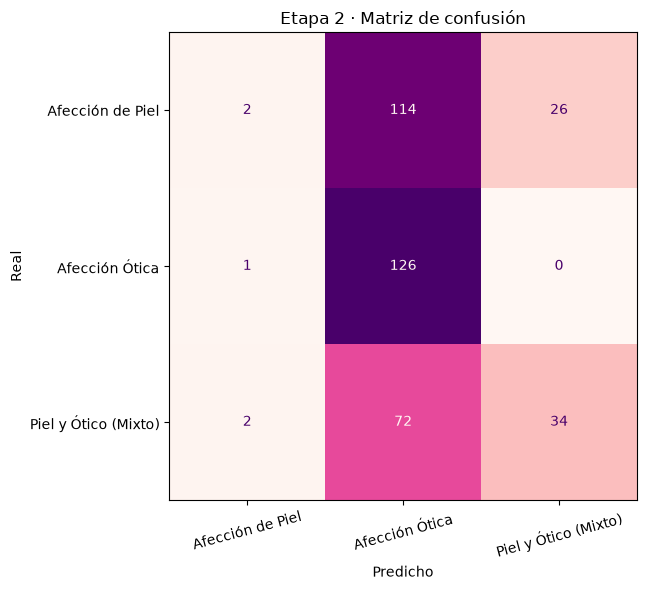

                      precision    recall  f1-score   support

    Afección de Piel      0.400     0.014     0.027       142
      Afección Ótica      0.404     0.992     0.574       127
Piel y Ótico (Mixto)      0.567     0.315     0.405       108

            accuracy                          0.430       377
           macro avg      0.457     0.440     0.335       377
        weighted avg      0.449     0.430     0.320       377



In [80]:
mejor_knn2 = busqueda2.best_estimator_
y2_pred = mejor_knn2.predict(X2_test)

print(f"Baseline:  {acc_baseline2:.1%}")
print(f"k-NN (k={busqueda2.best_params_['knn__n_neighbors']}): {accuracy_score(y2_test, y2_pred):.1%}")

cm2 = confusion_matrix(y2_test, y2_pred, labels=orden2)
display(pd.DataFrame(cm2, index=[f"real {c}" for c in orden2], columns=[f"pred {c}" for c in orden2]))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y2_test, y2_pred, labels=orden2, ax=ax, cmap="RdPu", colorbar=False)
ax.set_title("Etapa 2 · Matriz de confusión")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(classification_report(y2_test, y2_pred, labels=orden2, digits=3))

**Resultado de la etapa 2 (test, 377 pacientes enfermos; k = 200):**
- **Accuracy:** KNN 43,0 % contra baseline 33,7 % (+9 puntos): mejora real pero modesta.
- **Cómo la logra:** *Ótica* tiene recall 99 % (los pacientes con lámpara negativa se clasifican casi todos como "Ótica"); *Mixto* tiene recall 31 % (60 de los 63 pacientes con lámpara positiva se clasifican como "Mixto"); *Piel* tiene recall **1 %**: casi nunca la predice.
- En la práctica el KNN aprendió algo parecido a **"lámpara positiva → Mixto; negativa → Ótica"**. La lámpara de Wood es la única variable que dio información sobre el tipo de afección (vimos que en ótica es siempre negativa); las otras siete son casi iguales en los tres tipos y para el KNN son ruido.
- **¿En qué se equivoca?** Confunde Piel con Ótica (114 casos) y Mixto con Ótica (72).

## Conclusiones generales

**Datos y calidad.** Trabajamos con 2000 pacientes veterinarios y 15 columnas originales. Detectamos nulos estructurales y en variables como frecuencia cardíaca y condición corporal, los cuales fueron imputados correctamente. No hay duplicados ni valores imposibles.

**Qué aprendimos de los datos.**
- Solo el **5,8 % de los pacientes está sano**: el dataset está muy desbalanceado en estado de salud, pero las tres afecciones están casi igual de representadas.
- La **frecuencia cardíaca** depende de la especie; en gatos separa sanos de enfermos y en perros se solapa.
- La **lámpara de Wood positiva** solo aparece en afecciones con componente de piel.
- Las correlaciones lineales entre variables numéricas son débiles.

**Qué tan bien funciona el modelo.** Seguimos el flujo metodológico básico (baseline, escalado con `Pipeline`, `GridSearchCV` con `StratifiedKFold` y evaluación en test):

| Etapa | Baseline | k-NN |
|---|---|---|
| Etapa 1: sano vs. enfermo | 94,2 % | 95,0 % (k = 5) |
| Etapa 2: tipo de afección (solo enfermos) | 33,7 % | 43,0 % (k = 200) |

- **Etapa 1:** el accuracy es alto pero similar al baseline debido al desbalance de clases; el aporte del modelo es que logra detectar una porción de los pacientes sanos que el baseline ignoraba por completo.
- **Etapa 2:** se observa una mejora respecto al baseline, impulsada principalmente por las variables con mayor poder de discriminación biológica.
- **Escalar con `StandardScaler` fue clave** para evitar que las variables con números más grandes dominen el cálculo de distancias del k-NN.

**Limitación principal:** El desbalance severo en la primera etapa (pocos pacientes sanos en el conjunto de test) hace que las métricas en esa clase sean muy sensibles a pequeñas variaciones.